# Monitoramento e previsão de riscos hídricos na Região Metropolitana de São Paulo
**Global Solution 2026-2 — Data Science and Analytics (FIAP)**

**Integrantes:**
- Pedro Luis Tofoli — RM 564441
- Raphael Talarico Nascimento Silva — RM 565219
- Nelson Troccoli Santos Neto — RM 562815

> Data de referência dos dados: **04/11/2026** (último dia publicado pela Sabesp no momento da coleta).
> Este notebook é reprodutível: os dados brutos ficam em cache em `data/raw/` e podem ser baixados novamente das APIs públicas com `ATUALIZAR_DADOS = True`.

---
## 1. Problema e pergunta de pesquisa

A RMSP depende de sete sistemas produtores integrados (Cantareira, Alto Tietê, Guarapiranga, Rio Grande, Rio Claro, Cotia e São Lourenço). O **Sistema Cantareira** é o maior deles: tem cerca de 982 hm³ de volume útil e responde por aproximadamente metade do volume útil do sistema integrado. Foi também o sistema mais afetado na crise de 2014–2015, quando operou com o volume da reserva técnica. Em 2025 a região passou por uma nova estiagem: o Cantareira chegou a **19,3 % em 13/01/2026**.

**Pergunta de pesquisa:**
> *Com os dados públicos de armazenamento, chuva e vazões (2000–2026), é possível antecipar com **60 dias** de antecedência se o Sistema Cantareira estará abaixo de **40 % do volume útil**, ou seja, nas faixas de Alerta, Restrição ou Especial da Resolução Conjunta ANA/DAEE nº 925/2017? E qual é hoje a situação de risco dos sistemas produtores da RMSP?*

Perguntas auxiliares, investigadas na EDA:
1. Qual é o padrão sazonal de recarga e de deplecionamento?
2. Quanta chuva anual é necessária para manter o volume estável?
3. Com que defasagem a anomalia de chuva aparece no armazenamento?

**Escopo e responsabilidade.** A solução apoia a decisão; ela não decide. Os níveis de alerta são **recomendações para avaliação humana**. Nenhuma medida de restrição ou de racionamento deve ser tomada automaticamente a partir deles.

### Estrutura do notebook
1. Problema e pergunta · 2. Fontes e coleta · 3. Preparação e qualidade · 4. Integração com o SIBH · 5. Análise exploratória · 6. Indicadores · 7. Modelagem (regressão e classificação) · 8. Critérios de alerta · 9. Situação atual · 10. Conclusões, recomendações e limitações

In [1]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, root_mean_squared_error, r2_score,
                             precision_score, recall_score, fbeta_score,
                             average_precision_score, roc_auc_score, brier_score_loss,
                             confusion_matrix, precision_recall_curve)

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from coleta import baixar_sabesp, baixar_sibh, SISTEMAS, PARAMETROS
import analise as an

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

RAW, PROC, FIG = RAIZ / "data/raw", RAIZ / "data/processed", RAIZ / "outputs/figuras"
for p in (RAW, PROC, FIG):
    p.mkdir(parents=True, exist_ok=True)

ATUALIZAR_DADOS = False   # True = baixa novamente das APIs (substitui o cache em data/raw)
SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.titleweight": "bold", "axes.titlesize": 11})
CORES_SIS = dict(zip(SISTEMAS.values(), sns.color_palette("tab10", len(SISTEMAS))))
CN = an.CORES_NIVEIS

def salvar(fig, nome):
    fig.savefig(FIG / f"{nome}.png")

def faixas(ax, alpha=0.10):
    """Sombreia as faixas de nivel de alerta (eixo y em % do volume util)."""
    ax.axhspan(60, 200, color=CN["Normal"], alpha=alpha, lw=0)
    ax.axhspan(40, 60, color=CN["Atenção"], alpha=alpha, lw=0)
    ax.axhspan(30, 40, color=CN["Alerta"], alpha=alpha, lw=0)
    ax.axhspan(-100, 30, color=CN["Crítico"], alpha=alpha, lw=0)

---
## 2. Fontes de dados e coleta

As fontes sugeridas no enunciado foram investigadas. Duas oferecem **acesso automatizado verificável** e foram usadas. Em ambos os casos os endpoints foram identificados a partir das requisições feitas pelos próprios portais públicos. Não há autenticação nem raspagem de HTML.

| | **Fonte 1: Portal dos Mananciais (Sabesp)** | **Fonte 2: SIBH (SP Águas)** |
|---|---|---|
| Origem | https://mananciais.sabesp.com.br/base-dados | https://apps.spaguas.sp.gov.br/sibh/ |
| Acesso | API `GET /api/v4/elementos/{sistema}/dados/{parâmetro}/diario/{início}/{fim}` | API `GET /sibh/api/v1/measurements/grouped` (postos, datas, `group_type=day`) |
| Cobertura espacial | 7 sistemas produtores + Sistema Integrado Metropolitano (SIM) | 2 postos pluviométricos telemétricos na bacia do Cantareira: Piracaia (Cachoeira Montante, E3-269) e Nazaré Paulista (Atibainha Montante, E3-268) |
| Período | 01/01/2000 a 04/11/2026 (São Lourenço desde 04/2018) | 06/2015 a 11/2026, com lacunas |
| Frequência | Diária, atualizada diariamente | Diária (agregada a partir da telemetria) |
| Variáveis | volume útil (% e hm³), chuva diária, chuva média histórica do mês, vazões natural, afluente, captada e de jusante, vazão natural média histórica (MLT) | chuva (mm) |
| Limitações | todos os registros têm `isValid = false` (dado operacional não consistido); redefinições do volume útil ao longo do tempo; o SIM não publica chuva | só telemetria recente; os postos históricos do DAEE (ex.: E3-099, D3-054) não retornam dados por essa API; há meses incompletos |

**Fontes investigadas e não usadas:** Sala de Situação SP Águas e HidroApp/DAEE. Os painéis mostram a situação atual, mas não identificamos exportação histórica automatizável no prazo do projeto. Ficam como extensão futura, assim como o Banco de Dados Hidrológicos (séries históricas de postos).

**Critério de integração:** chave **data** (agregação mensal) + **localização**, com postos SIBH localizados nos reservatórios que formam o Cantareira.

A coleta está em `src/coleta.py`. Cada download é salvo em `data/raw/*.csv.gz` com um arquivo `.meta.json` (fonte, período, data e hora da coleta).

In [2]:
bruto = baixar_sabesp(RAW, force=ATUALIZAR_DADOS)
meta_sabesp = json.loads((RAW / "sabesp_mananciais_diario.meta.json").read_text(encoding="utf-8"))
ESTACOES_SIBH = {1431: "Piracaia (Cachoeira Montante) - Cantareira",
                 1398: "Nazare Paulista (Atibainha Montante) - Cantareira"}
sibh = baixar_sibh(RAW, ESTACOES_SIBH, inicio="2014-01-01", fim=meta_sabesp["fim"],
                   group_type="day", force=ATUALIZAR_DADOS)
print(f"Sabesp: {len(bruto):,} registros | {bruto.data.min():%d/%m/%Y} a {bruto.data.max():%d/%m/%Y} "
      f"| coletado em {meta_sabesp['coletado_em'][:10]}")
print(f"SIBH  : {len(sibh):,} registros diarios de chuva | {sibh.data.min():%d/%m/%Y} a {sibh.data.max():%d/%m/%Y}")
bruto.head()

Sabesp: 596,372 registros | 01/01/2000 a 04/11/2026 | coletado em 2026-11-05
SIBH  : 5,603 registros diarios de chuva | 12/06/2015 a 04/11/2026


,id_sistema,sistema,id_parametro,variavel,data,valor,is_valid
0,64,Cantareira,684,volume_pct,2000-01-01,47.11,False
1,64,Cantareira,684,volume_pct,2000-01-02,47.78,False
2,64,Cantareira,684,volume_pct,2000-01-03,48.59,False
3,64,Cantareira,684,volume_pct,2000-01-04,50.00,False
4,64,Cantareira,684,volume_pct,2000-01-05,51.95,False


In [3]:
cobertura = (bruto.groupby(["sistema", "variavel"])
             .agg(inicio=("data", "min"), fim=("data", "max"), registros=("valor", "count"))
             .reset_index())
cobertura["inicio"] = cobertura["inicio"].dt.strftime("%Y-%m-%d")
cobertura["fim"] = cobertura["fim"].dt.strftime("%Y-%m-%d")
cobertura.pivot(index="variavel", columns="sistema", values="inicio")

sistema,Alto Tietê,Cantareira,Cotia,Guarapiranga,Rio Claro,Rio Grande,SIM (Integrado),São Lourenço
variavel,,,,,,,,
chuva_media_hist_mm,2005-12-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,NaN,2018-04-04
chuva_mm,2004-12-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-03,NaN,2018-04-04
vazao_afluente_m3s,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2018-04-04
vazao_captada_m3s,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2018-04-04
vazao_jusante_m3s,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2001-05-01,NaN,2018-04-04
vazao_natural_m3s,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2018-04-04
vazao_natural_mlt_m3s,2006-06-01,2006-06-01,2006-06-01,2006-06-01,2006-06-01,2007-11-01,2000-01-01,2018-09-01
volume_hm3,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2018-04-04
volume_pct,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2000-01-01,2018-04-04


---
## 3. Preparação dos dados e verificação de qualidade

Etapas:
1. converter do formato longo (uma linha por sistema × variável × dia) para o largo (uma linha por sistema × dia) em um **calendário diário completo**, o que torna explícitos os dias ausentes;
2. diagnosticar ausências, valores negativos, extremos e o campo `isValid`;
3. detectar **quebras metodológicas**, isto é, mudanças na capacidade útil implícita (`volume_hm3 / volume_% × 100`), que indicam redefinição do volume útil, como a inclusão de reservatórios ou a revisão de cotas.

In [4]:
largo = an.formato_largo(bruto)
diag = []
for sis, g in largo.groupby("sistema"):
    g = g.set_index("data")
    diag.append({
        "sistema": sis, "dias": len(g),
        "dias_sem_volume": int(g.volume_pct.isna().sum()),
        "dias_sem_chuva": int(g.chuva_mm.isna().sum()) if g.chuva_mm.notna().any() else "n/d",
        "volume_negativo(dias)": int((g.volume_pct < 0).sum()),
        "vazao_natural_negativa(dias)": int((g.vazao_natural_m3s < 0).sum()),
        "chuva_max_dia(mm)": g.chuva_mm.max(),
        "quebras_metodologicas": (lambda q: f"{len(q)}: " + ", ".join(d.strftime("%Y-%m") for d in q[:3])
                                  + (" …" if len(q) > 3 else "") if len(q) else "-")(an.detectar_quebras(g)),
        "is_valid=True": int(bruto[(bruto.sistema == sis)].is_valid.sum()),
    })
diag = pd.DataFrame(diag).set_index("sistema")
diag

,dias,dias_sem_volume,dias_sem_chuva,volume_negativo(dias),vazao_natural_negativa(dias),chuva_max_dia(mm),quebras_metodologicas,is_valid=True
sistema,,,,,,,,
Alto Tietê,9805,0,1796,0,1010,99.47,"9: 2004-11, 2004-12, 2005-01 …",0
Cantareira,9805,0,0,538,2,102.00,1: 2004-09,0
Cotia,9805,0,0,0,6,121.40,1: 2002-04,0
Guarapiranga,9805,0,0,0,49,132.90,1: 2004-10,0
Rio Claro,9805,0,1,0,3,273.40,-,0
Rio Grande,9805,0,33,0,285,147.50,-,0
SIM (Integrado),9805,0,n/d,63,5,NaN,"8: 2004-09, 2004-11, 2004-12 …",0
São Lourenço,3137,0,0,0,0,108.80,-,0


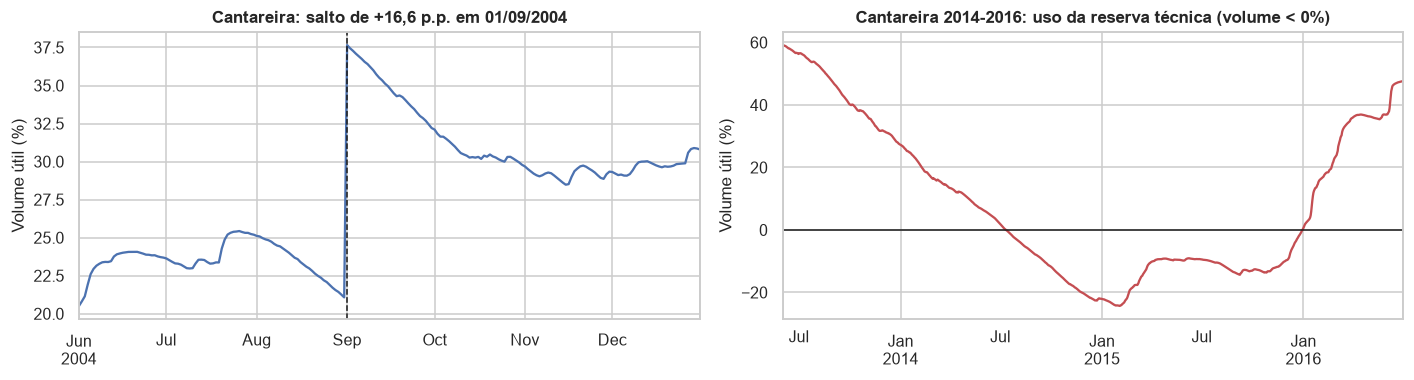

Capacidade útil implícita (hm³) antes/depois da quebra: 775 -> 984


In [5]:
cant_raw = largo[largo.sistema == "Cantareira"].set_index("data")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
cap = (cant_raw.volume_hm3 / (cant_raw.volume_pct / 100)).where(cant_raw.volume_pct.abs() > 5)
cant_raw.loc["2004-06":"2004-12", "volume_pct"].plot(ax=axes[0], color="C0")
axes[0].axvline(pd.Timestamp("2004-09-01"), color="k", ls="--", lw=1)
axes[0].set_title("Cantareira: salto de +16,6 p.p. em 01/09/2004")
axes[0].set_ylabel("Volume útil (%)"); axes[0].set_xlabel("")
cant_raw.loc["2013-06":"2016-06", "volume_pct"].plot(ax=axes[1], color="C3")
axes[1].axhline(0, color="k", lw=1)
axes[1].set_title("Cantareira 2014-2016: uso da reserva técnica (volume < 0%)")
axes[1].set_ylabel("Volume útil (%)"); axes[1].set_xlabel("")
plt.tight_layout(); salvar(fig, "01_qualidade_quebras"); plt.show()
print("Capacidade útil implícita (hm³) antes/depois da quebra:",
      round(cap.loc["2004-08"].median()), "->", round(cap.loc["2004-10"].median()))

**O que o diagnóstico mostra:**
- **Não há lacunas de volume** em nenhum sistema. Faltam dados de chuva no Alto Tietê antes de 12/2004 (1.796 dias) e no Rio Grande (33 dias). Chuva ausente **não é preenchida com zero**: os acumulados exigem pelo menos 90 % dos dias da janela.
- **`isValid = false` em 100 % dos registros.** A série é operacional e não foi consistida. Isso é uma limitação, mas é a fonte oficial usada nos boletins diários da Sabesp.
- **Quebras metodológicas.** No Cantareira, a capacidade útil implícita passou de **775 para 984 hm³ em 01/09/2004**, e o volume saltou 16,6 p.p. de um dia para o outro sem chuva. O efeito é contábil, não hidrológico. No Alto Tietê e no SIM aparecem várias quebras entre 2004 e 2018 (incorporação de reservatórios e entrada do São Lourenço em 2018). As quebras são registradas e **excluídas das janelas de modelagem**.
- **Volume negativo no Cantareira** (538 dias, mínimo de −24,3 %): é o uso da reserva técnica (o chamado "volume morto") em 2014–2015. O dado é real e foi mantido.
- **Vazão natural negativa** (1.010 dias no Alto Tietê, 285 no Rio Grande): a vazão natural é estimada por balanço hídrico e pode ficar negativa em dias secos, por causa de evaporação e erro de medição de nível. Os valores foram mantidos e os indicadores usam médias móveis de 30 e 90 dias, que suavizam esse ruído.
- **Extremos de chuva:** o maior valor diário é 273 mm (Rio Claro, na Serra do Mar). É plausível e foi mantido.

In [6]:
# Tratamentos (rastreaveis):
# 1) volume: lacunas de ate 3 dias interpoladas linearmente; chuva nao e interpolada.
# 2) quebras metodologicas registradas e usadas para excluir janelas de modelagem.
# 3) valores negativos de volume (reserva tecnica) e de vazao natural (balanco hidrico)
#    sao mantidos: sao informacao real; indicadores usam medias moveis de 30/90 dias.
trat = []
for sis, g in largo.groupby("sistema"):
    g = g.set_index("data").copy()
    antes = g.volume_pct.isna().sum()
    g["volume_pct"] = g.volume_pct.interpolate(limit=3, limit_area="inside")
    g["volume_hm3"] = g.volume_hm3.interpolate(limit=3, limit_area="inside")
    trat.append(g.assign(sistema=sis))
    if antes:
        print(f"{sis}: {antes} dias sem volume -> {g.volume_pct.isna().sum()} após interpolação")
diario = pd.concat(trat)
QUEBRAS = {s: an.detectar_quebras(g) for s, g in diario.groupby("sistema")}
diario.reset_index().to_csv(PROC / "sabesp_diario_tratado.csv.gz", index=False)
print("Arquivo salvo:", PROC / "sabesp_diario_tratado.csv.gz", "|", diario.shape)

Arquivo salvo: C:\Users\ntnet\OneDrive\Área de Trabalho\Projetos Vscode\faculdade\gs\GS - Data Science and Analytics\data\processed\sabesp_diario_tratado.csv.gz | (71772, 10)


---
## 4. Integração e validação cruzada com o SIBH (SP Águas)

A chuva publicada pela Sabesp para o Cantareira é uma média da bacia. Para checar essa série de forma independente, ela foi comparada com dois postos telemétricos da SP Águas instalados em reservatórios do próprio sistema. Os dois conjuntos foram cruzados por **mês**, e só entraram meses com **pelo menos 90 % dos dias** registrados no posto.

In [7]:
sibh_m = (sibh.assign(mes=sibh.data.dt.to_period("M"))
          .groupby(["posto", "mes"]).agg(chuva_mm=("chuva_mm", "sum"), dias=("chuva_mm", "count"))
          .reset_index())
sibh_m["completo"] = sibh_m.dias >= 0.9 * sibh_m.mes.dt.days_in_month
sab_m = (diario[diario.sistema == "Cantareira"].chuva_mm.resample("ME").sum()
         .to_period("M").rename("chuva_sabesp_mm"))
integ = sibh_m[sibh_m.completo].merge(sab_m, left_on="mes", right_index=True, how="inner")
resumo_integ = integ.groupby("posto").apply(lambda g: pd.Series({
    "meses_completos": len(g),
    "pearson_r": g.chuva_mm.corr(g.chuva_sabesp_mm),
    "spearman_rho": g.chuva_mm.corr(g.chuva_sabesp_mm, method="spearman"),
    "vies_medio_mm": (g.chuva_mm - g.chuva_sabesp_mm).mean(),
    "razao_totais": g.chuva_mm.sum() / g.chuva_sabesp_mm.sum()}), include_groups=False)
print(f"Meses descartados por cobertura < 90% dos dias: {(~sibh_m.completo).sum()} de {len(sibh_m)}")
resumo_integ

Meses descartados por cobertura < 90% dos dias: 10 de 189

,meses_completos,pearson_r,spearman_rho,vies_medio_mm,razao_totais
posto,,,,,
Nazare Paulista (Atibainha Montante) - Cantareira,50.00,0.92,0.95,19.95,1.18
Piracaia (Cachoeira Montante) - Cantareira,129.00,0.92,0.94,-10.35,0.91


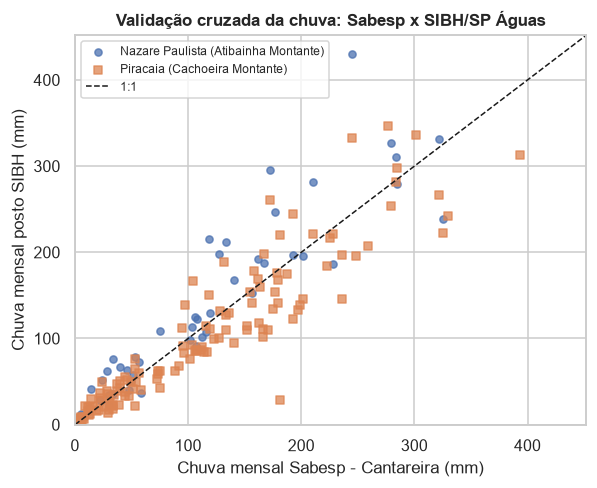

In [8]:
fig, ax = plt.subplots(figsize=(6, 4.6))
for (p, g), m in zip(integ.groupby("posto"), ["o", "s"]):
    ax.scatter(g.chuva_sabesp_mm, g.chuva_mm, s=22, alpha=0.75, marker=m, label=p.split(" - ")[0])
lim = max(integ.chuva_mm.max(), integ.chuva_sabesp_mm.max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1, label="1:1")
ax.set(xlabel="Chuva mensal Sabesp - Cantareira (mm)", ylabel="Chuva mensal posto SIBH (mm)",
       title="Validação cruzada da chuva: Sabesp x SIBH/SP Águas", xlim=(0, lim), ylim=(0, lim))
ax.legend(fontsize=8); salvar(fig, "02_sabesp_x_sibh"); plt.show()

**Resultado da integração:** a chuva mensal da Sabesp e a dos postos independentes têm **correlação de Pearson de 0,92** (Spearman de 0,94 a 0,95) nos dois postos. A diferença de nível (razão entre totais de 0,91 em Piracaia e 1,18 em Nazaré Paulista) é esperada ao comparar um ponto com a média de uma bacia. Isso aumenta a confiança na série de chuva da Sabesp, que é a usada nos indicadores e nos modelos. O SIBH serve como **validação externa**, não como variável do modelo, porque cobre só o período a partir de 2015.

---
## 5. Análise exploratória (EDA)

### 5.1 Estatística descritiva do volume útil por sistema

In [9]:
ultima = diario.index.max()
desc = (diario.groupby("sistema").volume_pct
        .describe(percentiles=[.1, .5, .9])[["count", "mean", "std", "min", "10%", "50%", "90%", "max"]])
desc["atual"] = diario[diario.index == ultima].set_index("sistema").volume_pct
desc["dias<40%"] = diario.assign(b=diario.volume_pct < 40).groupby("sistema").b.mean() * 100
desc["capacidade_hm3"] = (diario[diario.index == ultima].set_index("sistema").volume_hm3
                          / (desc["atual"] / 100))
desc.round(1)

,count,mean,std,min,10%,50%,90%,max,atual,dias<40%,capacidade_hm3
sistema,,,,,,,,,,,
Alto Tietê,"9,805.00",51.50,18.30,4.20,24.70,52.10,76.10,101.30,60.50,23.90,560.30
Cantareira,"9,805.00",46.60,24.60,-24.30,16.80,46.70,78.90,100.50,52.50,35.70,982.10
Cotia,"9,805.00",71.80,26.00,5.30,31.30,78.20,101.10,110.50,102.70,14.60,16.50
Guarapiranga,"9,805.00",65.60,18.10,18.60,39.60,69.10,86.90,98.00,89.80,10.40,171.20
Rio Claro,"9,805.00",71.60,26.50,9.30,37.20,74.20,102.00,108.00,60.70,13.80,13.70
Rio Grande,"9,805.00",86.50,10.60,51.50,72.50,88.70,98.60,108.50,96.20,0.00,112.20
SIM (Integrado),"9,805.00",53.10,19.00,-3.20,27.60,53.60,76.10,100.20,62.10,21.20,"1,944.70"
São Lourenço,"3,137.00",75.10,19.00,22.90,49.80,74.80,98.30,102.10,74.20,3.40,88.80


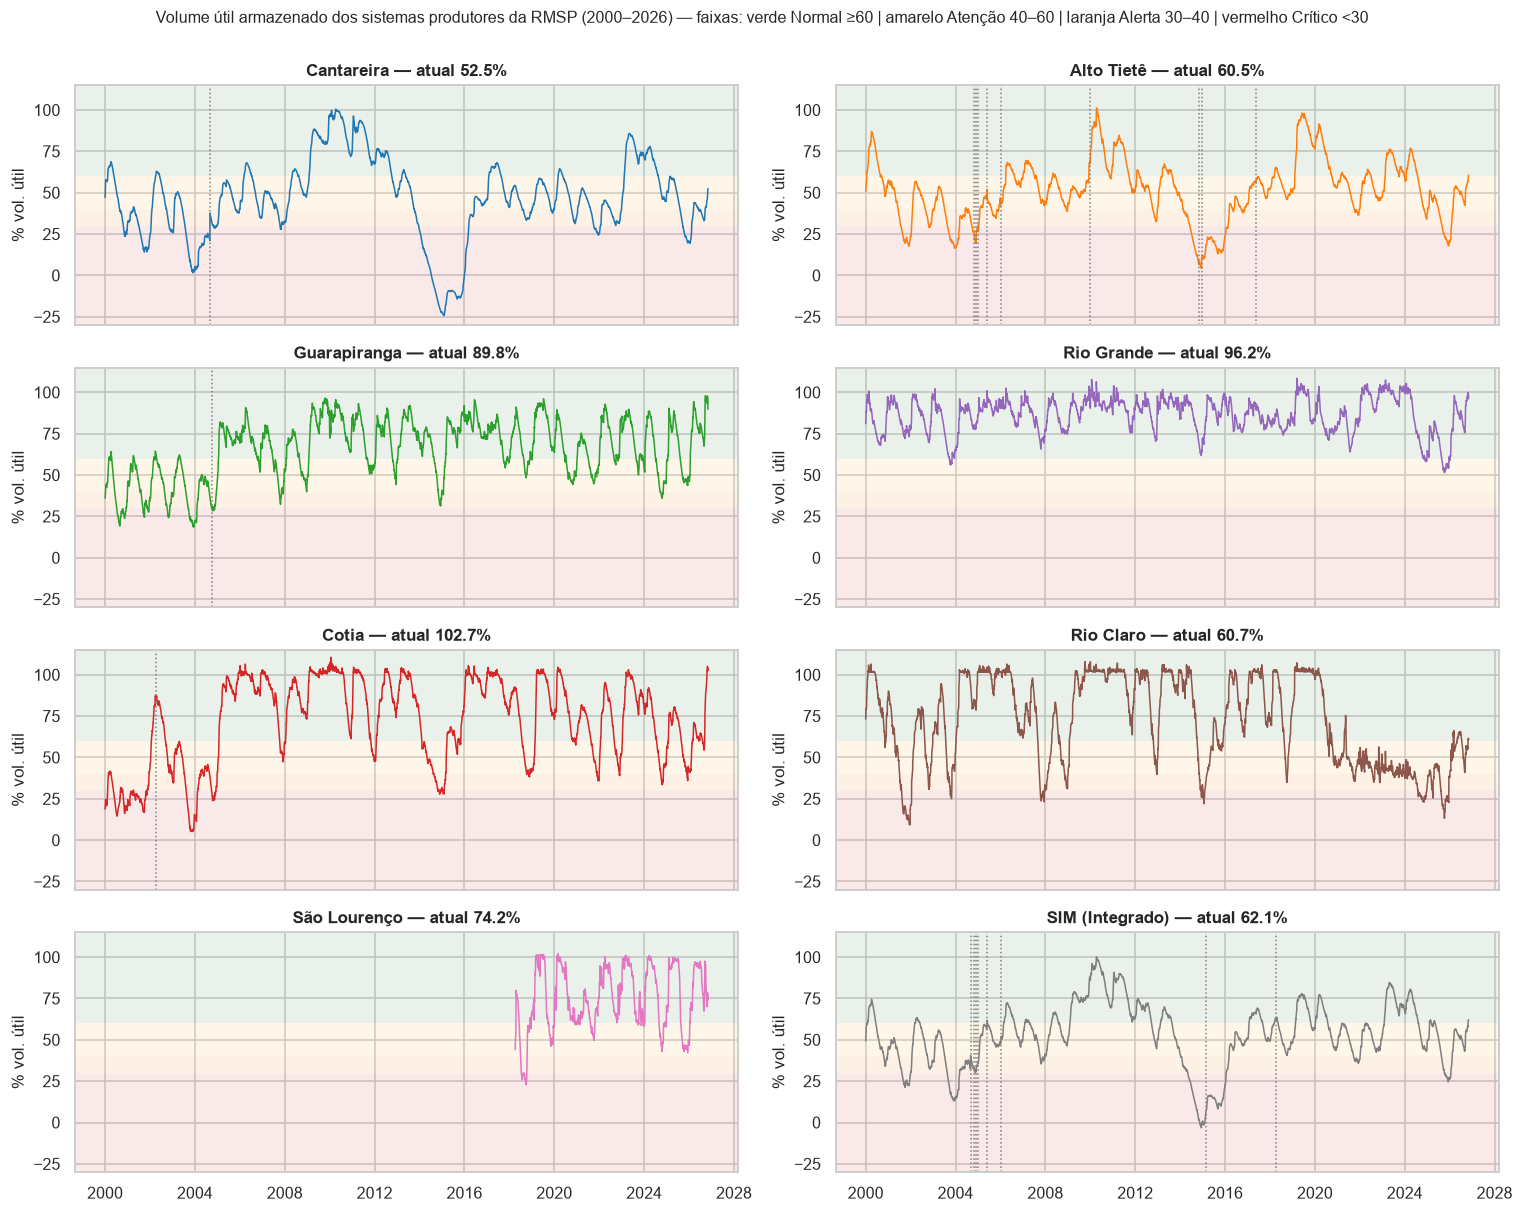

In [10]:
ordem = ["Cantareira", "Alto Tietê", "Guarapiranga", "Rio Grande", "Cotia", "Rio Claro",
         "São Lourenço", "SIM (Integrado)"]
fig, axes = plt.subplots(4, 2, figsize=(14, 11), sharex=True)
for ax, sis in zip(axes.flat, ordem):
    g = diario[diario.sistema == sis]
    faixas(ax)
    ax.plot(g.index, g.volume_pct, color=CORES_SIS[sis], lw=1)
    for q in QUEBRAS[sis]:
        ax.axvline(q, color="grey", ls=":", lw=1)
    ax.set_title(f"{sis} — atual {g.volume_pct.iloc[-1]:.1f}%")
    ax.set_ylim(min(-30, g.volume_pct.min() - 5), 115); ax.set_ylabel("% vol. útil")
for ax in axes[-1]:
    ax.xaxis.set_major_locator(mdates.YearLocator(4))
fig.suptitle("Volume útil armazenado dos sistemas produtores da RMSP (2000–2026) — faixas: "
             "verde Normal ≥60 | amarelo Atenção 40–60 | laranja Alerta 30–40 | vermelho Crítico <30",
             fontsize=10.5, y=1.0)
plt.tight_layout(); salvar(fig, "03_volume_sistemas"); plt.show()

**Interpretação:**
- O **Cantareira** é o sistema mais vulnerável: passou **35,7 % dos dias desde 2000 abaixo de 40 %**, com média de 46,6 % e desvio de 24,6 p.p. O Alto Tietê vem em seguida, com 23,9 %. Guarapiranga e Rio Grande raramente ficam baixos.
- Há quatro crises claras: **2003–2004**, **2014–2015** (reserva técnica), **2021–2022** e **2025**. Na última, os mínimos foram: Cantareira 19,3 % (13/01/2026), Alto Tietê 18,0 % (12/12/2025), Rio Claro 13,1 % (07/10/2025) e SIM 24,6 % (09/12/2025).
- As crises são **sincronizadas entre os sistemas**, porque a mesma estiagem regional atinge todos. A integração entre sistemas tem portanto limite como mecanismo de compensação.
- O Rio Claro opera em patamar mais baixo desde 2020 (em torno de 40–60 %), possivelmente por mudança operacional. Isso merece verificação junto à Sabesp.

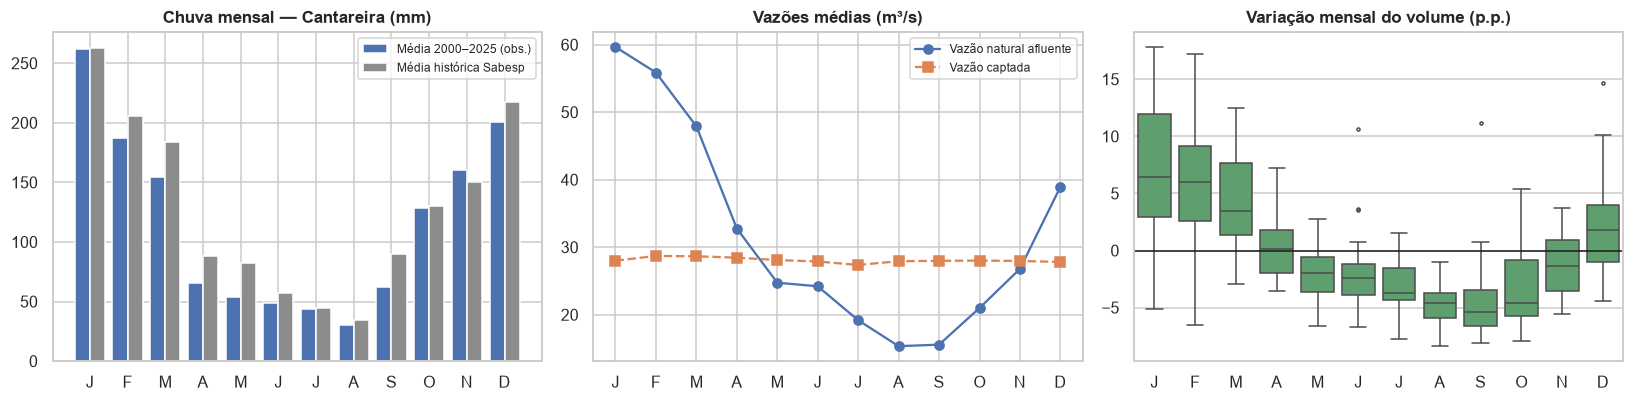

mes,1,2,3,4,5,6,7,8,9,10,11,12
chuva_obs,262.30,187.50,154.50,65.90,53.70,49.00,44.00,30.30,62.20,128.70,160.20,200.60
chuva_hist,263.00,205.90,184.10,88.40,82.60,57.00,45.00,34.60,89.70,130.20,150.40,217.80
vazao_nat,59.70,55.90,47.90,32.80,24.70,24.20,19.20,15.30,15.60,21.00,26.80,38.90
captada,28.00,28.70,28.70,28.40,28.10,27.90,27.40,27.90,28.00,28.00,28.00,27.80
dV_medio,7.10,5.80,4.20,0.30,-2.00,-1.80,-3.40,-4.80,-4.30,-3.40,-1.30,2.30


In [11]:
cant = diario[diario.sistema == "Cantareira"].copy()
cant["mes"] = cant.index.month
mensal = cant.resample("ME").agg({"chuva_mm": "sum", "chuva_media_hist_mm": "first",
                                  "vazao_natural_m3s": "mean", "vazao_captada_m3s": "mean",
                                  "volume_pct": "last"})
mensal["dV"] = mensal.volume_pct.diff()
mensal["mes"] = mensal.index.month
clima = mensal.loc[:"2025-12"].groupby("mes").agg(
    chuva_obs=("chuva_mm", "mean"), chuva_hist=("chuva_media_hist_mm", "median"),
    vazao_nat=("vazao_natural_m3s", "mean"), captada=("vazao_captada_m3s", "mean"),
    dV_medio=("dV", "mean"))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
x = np.arange(1, 13); meses = list("JFMAMJJASOND")
axes[0].bar(x - 0.2, clima.chuva_obs, 0.4, label="Média 2000–2025 (obs.)", color="C0")
axes[0].bar(x + 0.2, clima.chuva_hist, 0.4, label="Média histórica Sabesp", color="C7")
axes[0].set(title="Chuva mensal — Cantareira (mm)", xticks=x, xticklabels=meses); axes[0].legend(fontsize=8)
axes[1].plot(x, clima.vazao_nat, "o-", label="Vazão natural afluente")
axes[1].plot(x, clima.captada, "s--", label="Vazão captada")
axes[1].set(title="Vazões médias (m³/s)", xticks=x, xticklabels=meses); axes[1].legend(fontsize=8)
sns.boxplot(data=mensal.loc[:"2025-12"], x="mes", y="dV", ax=axes[2], color="C2", fliersize=2)
axes[2].axhline(0, color="k", lw=1)
axes[2].set(title="Variação mensal do volume (p.p.)", xlabel="", ylabel="", xticks=range(12), xticklabels=meses)
plt.tight_layout(); salvar(fig, "04_sazonalidade_cantareira"); plt.show()
clima.round(1).T

**Interpretação (sazonalidade do Cantareira):**
- O regime é tropical: **outubro a março** concentram cerca de 78 % da chuva, e janeiro tem em média 262 mm. **Abril a setembro** é a estação seca, com agosto em torno de 30 mm.
- A vazão natural afluente vai de cerca de 60 m³/s em janeiro a cerca de 15 m³/s em agosto e setembro. A captação é praticamente constante (cerca de 28 m³/s). **De maio a outubro a captação supera a afluência**, e o volume cai em média 2 a 5 p.p. por mês.
- O volume só sobe, em média, de **dezembro a março**. Por isso **o volume no fim de março é o principal determinante do risco no ano seguinte**: uma estação chuvosa fraca deixa o sistema entrar na seca com pouca reserva.
- A chuva observada em 2000–2025 ficou abaixo da média histórica de longo prazo da Sabesp em quase todos os meses (fevereiro: 187 contra 206 mm; março: 154 contra 184 mm). Isso sugere um período mais seco que a referência histórica.

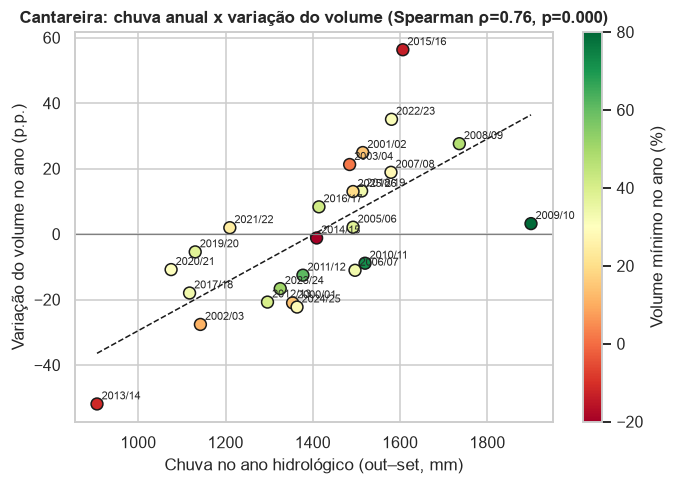

Pearson r=0.70 (p=0.0001); inclinação: 7.3 p.p. a cada 100 mm de chuva; chuva de equilíbrio (dV=0) ≈ 1402 mm


,chuva,dias,v_ini,v_fim,v_min,dV
ano_hidro,,,,,,
2014,905.40,365,40.20,-11.70,-11.70,-51.90
2021,"1,075.20",365,41.20,30.40,30.40,-10.80
2018,"1,117.60",365,51.60,33.60,33.60,-18.00
2020,"1,130.50",366,46.90,41.50,37.70,-5.40
2003,"1,142.40",365,38.80,11.20,11.20,-27.60
2022,"1,209.80",365,30.10,32.10,24.30,2.00


In [12]:
# Ano hidrologico (out -> set): chuva total x variacao de volume no ano
cant["ano_hidro"] = np.where(cant.index.month >= 10, cant.index.year + 1, cant.index.year)
ah = cant.groupby("ano_hidro").agg(chuva=("chuva_mm", "sum"), dias=("chuva_mm", "count"),
                                   v_ini=("volume_pct", "first"), v_fim=("volume_pct", "last"),
                                   v_min=("volume_pct", "min"))
ah = ah[(ah.dias >= 360) & (ah.index != 2005)]   # anos completos; 2004/05 contem a quebra metodologica
ah["dV"] = ah.v_fim - ah.v_ini
rho, p_rho = stats.spearmanr(ah.chuva, ah.dV)
r, p_r = stats.pearsonr(ah.chuva, ah.dV)
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.scatter(ah.chuva, ah.dV, c=ah.v_min, cmap="RdYlGn", vmin=-20, vmax=80, s=60, edgecolor="k")
for a, row in ah.iterrows():
    ax.annotate(f"{a-1}/{str(a)[2:]}", (row.chuva, row.dV), fontsize=7, xytext=(3, 3), textcoords="offset points")
b = np.polyfit(ah.chuva, ah.dV, 1)
xx = np.linspace(ah.chuva.min(), ah.chuva.max(), 10); ax.plot(xx, np.polyval(b, xx), "k--", lw=1)
ax.axhline(0, color="grey", lw=0.8)
ax.set(xlabel="Chuva no ano hidrológico (out–set, mm)", ylabel="Variação do volume no ano (p.p.)",
       title=f"Cantareira: chuva anual x variação do volume (Spearman ρ={rho:.2f}, p={p_rho:.3f})")
sm = plt.cm.ScalarMappable(cmap="RdYlGn", norm=plt.Normalize(-20, 80)); fig.colorbar(sm, ax=ax, label="Volume mínimo no ano (%)")
salvar(fig, "05_chuva_anual_x_volume"); plt.show()
print(f"Pearson r={r:.2f} (p={p_r:.4f}); inclinação: {b[0]*100:.1f} p.p. a cada 100 mm de chuva; "
      f"chuva de equilíbrio (dV=0) ≈ {-b[1]/b[0]:.0f} mm")
ah.sort_values("chuva").head(6).round(1)

**Interpretação (balanço anual):**
- A chuva do ano hidrológico explica boa parte da variação anual do volume: **Pearson r = 0,70 (p < 0,001); Spearman ρ = 0,76**. Cada 100 mm a mais de chuva equivale a cerca de **+7,3 p.p.** de volume ao fim do ano.
- A **chuva de equilíbrio**, em que o volume se mantém estável com a captação atual, é de **cerca de 1.400 mm/ano**. Esse valor está **acima da média observada no período**. Em boa parte dos anos o sistema precisa de chuva acima da média só para não perder volume, o que mostra o quanto a captação está próxima da capacidade de recarga.
- Os anos mais secos (2013/14 com 905 mm, 2020/21, 2017/18, 2002/03) são justamente os de maior perda de volume.

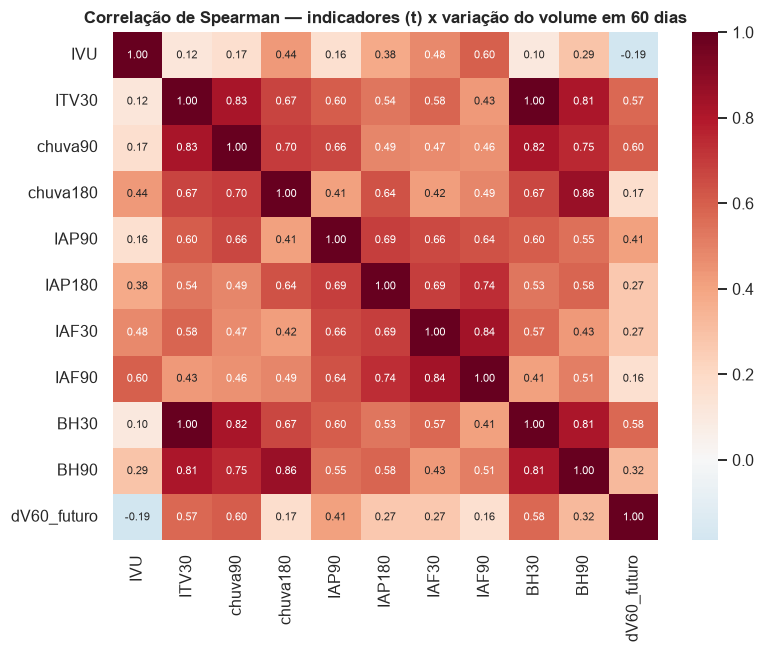

Spearman IAP90(t) x ITV90(t+lag): {0: np.float64(0.54), 15: np.float64(0.6), 30: np.float64(0.61), 45: np.float64(0.6), 60: np.float64(0.56), 75: np.float64(0.5), 90: np.float64(0.41), 105: np.float64(0.34), 120: np.float64(0.26), 135: np.float64(0.17), 150: np.float64(0.1), 165: np.float64(0.03), 180: np.float64(-0.05)}


In [13]:
# Relacao entre anomalias de chuva/vazao acumuladas e a variacao futura do volume
ind_c = an.calcular_indicadores(cant)
fut = pd.DataFrame({"dV60_futuro": ind_c.IVU.shift(-60) - ind_c.IVU})
cor = ind_c[["IVU", "ITV30", "chuva90", "chuva180", "IAP90", "IAP180", "IAF30", "IAF90", "BH30", "BH90"]].join(fut)
cor = cor.loc["2005-09-01":]
spear = cor.corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(spear, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, annot_kws={"size": 7.5})
ax.set_title("Correlação de Spearman — indicadores (t) x variação do volume em 60 dias")
salvar(fig, "06_correlacoes"); plt.show()

# defasagem: em quanto tempo a chuva se reflete no volume?
lags = range(0, 181, 15)
cc = [stats.spearmanr(ind_c.IAP90.loc["2001":], ind_c.ITV90.shift(-l).loc["2001":], nan_policy="omit")[0] for l in lags]
print("Spearman IAP90(t) x ITV90(t+lag):", dict(zip(lags, np.round(cc, 2))))

In [14]:
# Teste: chuva da estacao umida (out-mar) antes dos anos que terminaram em Alerta/Critico
um = cant[cant.index.month.isin([10, 11, 12, 1, 2, 3])].groupby("ano_hidro").chuva_mm.agg(["sum", "count"])
um = um[um["count"] >= 175]["sum"]
crise = ah.v_min < 30
g1, g2 = um.reindex(ah.index[crise]).dropna(), um.reindex(ah.index[~crise]).dropna()
u = stats.mannwhitneyu(g1, g2, alternative="less")
print(f"Chuva da estação úmida — anos com volume mínimo < 30%: mediana {g1.median():.0f} mm (n={len(g1)}) | "
      f"demais anos: {g2.median():.0f} mm (n={len(g2)}) | Mann-Whitney unilateral p={u.pvalue:.3f}")

Chuva da estação úmida — anos com volume mínimo < 30%: mediana 1020 mm (n=11) | demais anos: 1118 mm (n=14) | Mann-Whitney unilateral p=0.131


**Interpretação (correlações e defasagem):**
- A variação do volume nos 60 dias seguintes está mais associada às **condições recentes** (tendência de 30 dias, balanço hídrico de 30 e 90 dias, chuva e afluência de 90 dias) e à **época do ano** do que ao nível atual.
- A anomalia de chuva de 90 dias (IAP90) tem a maior correlação com a variação do volume nos 90 dias seguintes quando a defasagem é de **15 a 45 dias** (ρ ≈ 0,60). A resposta do reservatório chega com cerca de um mês de atraso, porque o solo precisa saturar antes de a chuva escoar. A correlação desaparece depois de cerca de 150 dias. Isso define o horizonte útil de previsão: **30 a 90 dias**.
- **Teste de hipótese (Mann-Whitney unilateral):** a chuva da estação úmida nos anos que terminaram com volume abaixo de 30 % tem mediana de 1.020 mm, contra 1.118 mm nos demais anos. A diferença vai na direção esperada, mas **não é significativa (p = 0,13; n = 11 contra 14)**. A chuva de uma única estação não basta para explicar as crises: elas resultam da **combinação de volume inicial baixo com chuva abaixo da média**, o que justifica indicadores e modelos multivariados.

---
## 6. Indicadores de situação hídrica

Todos os indicadores são calculados **diariamente e por sistema** (`src/analise.py → calcular_indicadores`), usando apenas informação disponível até o dia *t*.

| Indicador | Definição / fórmula | Unidade | Periodicidade | Interpretação |
|---|---|---|---|---|
| **IVU**: Índice de Volume Útil | $IVU_t = 100 \cdot V_{útil,t} / V_{útil,máx}$ (publicado pela Sabesp) | % | diária | estado do estoque; < 40 % indica Alerta (faixas da Res. ANA/DAEE 925/2017) |
| **ITV30**: Tendência do volume | $IVU_t - IVU_{t-30}$ (também calculado para 7 e 90 dias) | p.p./30 dias | diária | negativo indica deplecionamento; a intensidade mostra a velocidade da queda |
| **IAP90**: Anomalia de precipitação | $100 \cdot \sum_{90d} P_{obs} / \sum_{90d} P_{hist}$ (média histórica mensal da Sabesp, rateada por dia) | % da média | diária | < 100 % significa chuva abaixo do normal; < 60 % indica seca severa |
| **IAF90**: Índice de afluência | $100 \cdot \overline{Q}_{nat,90d} / \overline{Q}_{MLT,90d}$ | % da MLT | diária | afluência natural em relação à média de longo termo; incorpora a resposta do solo |
| **BH30**: Balanço hídrico | $\sum_{30d}(Q_{afl} - Q_{capt} - Q_{jus}) \times 0{,}0864$ | hm³/30 dias | diária | negativo indica que a retirada supera a entrada |
| **AUT**: Autonomia | $V_{útil}(hm^3) / \text{déficit médio diário dos últimos 30 dias}$ | dias | diária | dias até esgotar o volume útil se o déficit recente continuar; "sem déficit" quando BH30 ≥ 0 |
| **IRH**: Índice integrado de Risco Hídrico | $\sum_k w_k \cdot 100 \cdot (1 - F_k(x_k))$, com $F_k$ = percentil empírico do próprio sistema em 2001–2020; pesos: IVU 0,45, IAP90 0,20, IAF90 0,20, ITV30 0,15 (redistribuídos quando um componente falta) | 0–100 | diária | ≥ 75 indica pressão hídrica elevada em relação ao histórico do sistema |

**Justificativa dos pesos do IRH:** o estoque (IVU) recebe o maior peso porque é o estado que de fato limita o abastecimento. Chuva e afluência entram como pressões que antecedem mudanças no estoque, e a tendência captura a velocidade da mudança. O uso de percentis por sistema torna sistemas de porte muito diferente comparáveis (Cotia tem cerca de 16 hm³; Cantareira, 982 hm³).

In [15]:
inds = {}
for sis, g in diario.groupby("sistema"):
    i = an.calcular_indicadores(g.drop(columns="sistema"))
    i["IRH"] = an.calcular_irh(i)
    i["nivel_volume"] = i.IVU.map(an.nivel_por_volume)
    inds[sis] = i
indicadores = pd.concat({s: i for s, i in inds.items()}, names=["sistema", "data"])
indicadores.reset_index().to_csv(PROC / "indicadores_diarios.csv.gz", index=False)

cols = ["IVU", "ITV30", "IAP90", "IAF90", "BH30", "AUT", "IRH", "nivel_volume"]
atual = indicadores.xs(ultima, level="data")[cols].reindex(ordem)
atual

,IVU,ITV30,IAP90,IAF90,BH30,AUT,IRH,nivel_volume
sistema,,,,,,,,
Cantareira,52.52,11.36,211.81,171.57,111.93,NaN,18.41,Atenção
Alto Tietê,60.48,6.19,239.80,261.23,32.00,NaN,13.15,Normal
Guarapiranga,89.77,-5.32,261.35,289.29,-9.10,506.58,13.89,Normal
Rio Grande,96.20,1.34,250.98,194.00,1.34,NaN,11.43,Normal
Cotia,102.65,11.38,278.99,317.54,-3.49,145.46,9.39,Normal
Rio Claro,60.74,5.03,166.92,174.18,8.84,NaN,49.25,Normal
São Lourenço,74.23,-5.27,241.02,163.99,-4.68,422.79,30.23,Normal
SIM (Integrado),62.09,7.02,NaN,195.26,304.38,NaN,20.52,Normal


**Leitura dos indicadores em 04/11/2026:** depois de um setembro e um outubro muito chuvosos (IAP90 de 212 % no Cantareira e acima de 165 % em todos os sistemas), **todos os sistemas estão com balanço positivo ou próximo de zero e IRH baixo** (9 a 49). O Cantareira ganhou 11,4 p.p. em 30 dias, mas continua na faixa de **Atenção (52,5 %)**, porque partiu de níveis muito baixos.

### 6.1 Validação do IRH: o índice antecipa volume baixo 60 dias depois?

In [16]:
# Validacao do IRH: o indice em t antecipa queda/baixo volume em t+60?
val_irh = []
for sis, i in inds.items():
    f = i.IVU.shift(-60)
    m = pd.DataFrame({"IRH": i.IRH, "fut": f, "dV": f - i.IVU}).dropna()
    ev = (m.fut < 40)
    val_irh.append({"sistema": sis, "n": len(m),
                    "rho_IRH_x_V(t+60)": stats.spearmanr(m.IRH, m.fut)[0],
                    "rho_IRH_x_dV60": stats.spearmanr(m.IRH, m.dV)[0],
                    "%_dias_evento(V<40)": ev.mean() * 100,
                    "AUC_IRH_evento": roc_auc_score(ev, m.IRH) if 0 < ev.mean() < 1 else np.nan,
                    "AUC_só_volume_atual": roc_auc_score(ev, -i.IVU.reindex(m.index)) if 0 < ev.mean() < 1 else np.nan})
pd.DataFrame(val_irh).set_index("sistema").reindex(ordem).round(3)

,n,rho_IRH_x_V(t+60),rho_IRH_x_dV60,%_dias_evento(V<40),AUC_IRH_evento,AUC_só_volume_atual
sistema,,,,,,
Cantareira,9745,-0.84,-0.17,35.97,0.90,0.93
Alto Tietê,9745,-0.79,-0.04,24.00,0.91,0.94
Guarapiranga,9745,-0.73,0.16,10.38,0.90,0.93
Rio Grande,9745,-0.63,0.26,0.00,NaN,NaN
Cotia,9745,-0.84,-0.03,14.13,0.91,0.96
Rio Claro,9745,-0.80,0.11,13.88,0.89,0.89
São Lourenço,3077,-0.57,0.26,3.44,0.78,0.83
SIM (Integrado),9745,-0.88,-0.01,21.36,0.96,0.96


**Interpretação (avaliação crítica do IRH):**
- O IRH em *t* tem correlação forte com o volume em *t+60* (ρ de −0,57 a −0,88) e AUC de 0,78 a 0,96 para identificar volume abaixo de 40 % em 60 dias.
- **Porém o IRH não supera o próprio volume atual como discriminador** (AUC do volume isolado entre 0,83 e 0,96). Para essa tarefa específica, o estoque atual já carrega quase toda a informação. Por isso o IRH **não foi usado como gatilho automático de alerta** (ver seção 8).
- O IRH continua útil para **comunicação e monitoramento**: ele mostra quando chuva e afluência estão anormalmente baixas *antes* de o volume cair. No gráfico abaixo, ele passou de 75 em 2013 e em meados de 2025, alguns meses antes dos mínimos de volume.

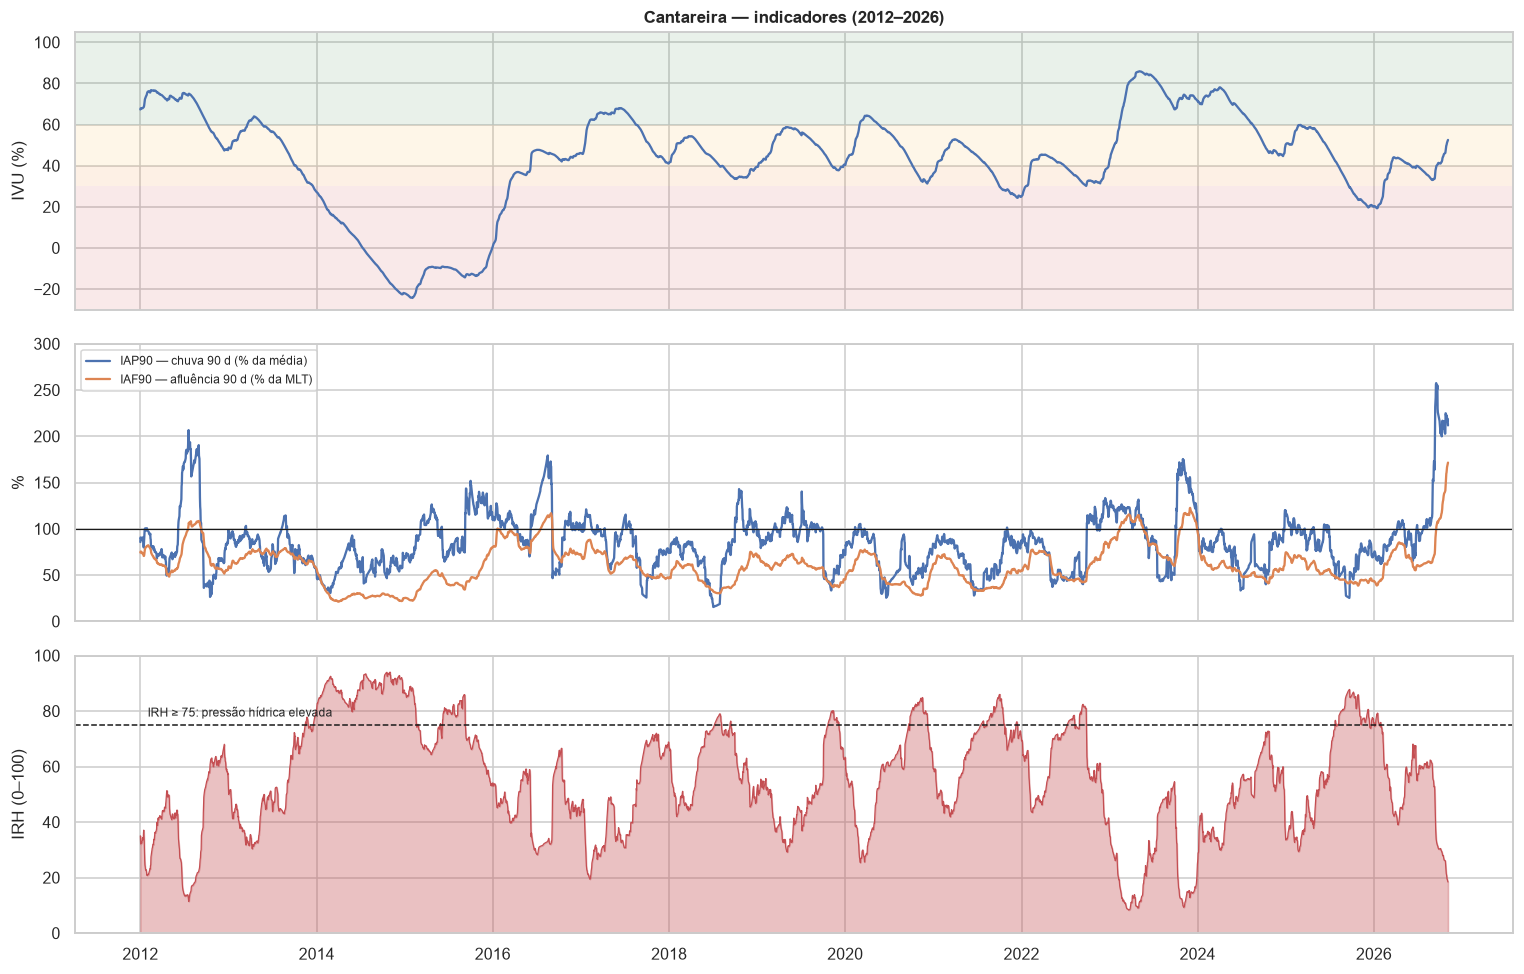

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
ic = inds["Cantareira"].loc["2012":]
faixas(axes[0]); axes[0].plot(ic.index, ic.IVU, color="C0"); axes[0].set_ylabel("IVU (%)"); axes[0].set_ylim(-30, 105)
axes[0].set_title("Cantareira — indicadores (2012–2026)")
axes[1].plot(ic.index, ic.IAP90, label="IAP90 — chuva 90 d (% da média)", color="C0")
axes[1].plot(ic.index, ic.IAF90, label="IAF90 — afluência 90 d (% da MLT)", color="C1")
axes[1].axhline(100, color="k", lw=0.8); axes[1].set_ylabel("%"); axes[1].legend(fontsize=8, loc="upper left")
axes[1].set_ylim(0, 300)
axes[2].fill_between(ic.index, ic.IRH, color="C3", alpha=0.35); axes[2].plot(ic.index, ic.IRH, color="C3", lw=0.8)
axes[2].axhline(75, color="k", ls="--", lw=1); axes[2].set_ylabel("IRH (0–100)"); axes[2].set_ylim(0, 100)
axes[2].text(ic.index[30], 78, "IRH ≥ 75: pressão hídrica elevada", fontsize=8)
plt.tight_layout(); salvar(fig, "07_indicadores_cantareira"); plt.show()

---
## 7. Modelagem analítica e preditiva (Sistema Cantareira)

**Por que o Cantareira:** é o maior sistema, é o único com faixas operacionais regulatórias (Res. ANA/DAEE 925/2017) e tem histórico contínuo desde 2000, com uma única quebra metodológica (2004). Nos demais sistemas o monitoramento usa os indicadores.

**Desenho experimental, para evitar vazamento de informação:**
- *Features* (17) disponíveis em *t*: IVU, ITV7/30/90, chuva acumulada de 30/90/180/365 dias, IAP90/180, IAF30/90, BH30/90, captação média de 30 dias e sazonalidade (seno e cosseno do dia do ano).
- **Divisão cronológica com embargo**: treino 2000–2016 (inclui as crises de 2003 e 2014–15), validação 2017–2020 (ajuste de hiperparâmetros, limiares e da regra de alerta) e **teste 2021–2026** (crises de 2021, 2022 e 2025, nunca vistas no ajuste). O alvo *t+h* de um bloco nunca entra no bloco seguinte.
- Amostras cuja janela [t−365, t+h] cruza a quebra de 01/09/2004 foram excluídas.
- Depois da escolha na validação, os modelos são reajustados com treino e validação juntos e avaliados **uma única vez** no teste.

**Modelos (duas abordagens, dois algoritmos cada):**
1. **Regressão**: prevê a variação ΔV(t→t+h) para h = 30, 60 e 90 dias. *Ridge* é um modelo linear regularizado e interpretável. *Random Forest* é não linear e captura interações, por exemplo o efeito da chuva depender da estação do ano.
2. **Classificação**: prevê o evento **V(t+60) < 40 %** (Alerta ou pior). *Regressão logística* com classes balanceadas contra *Random Forest* com classes balanceadas.

Também foram avaliados **baselines** (persistência e climatologia sazonal). Um modelo só se justifica se superar referências simples.

In [18]:
ind_model = inds["Cantareira"]
quebras_c = QUEBRAS["Cantareira"]
HORIZONTES = [30, 60, 90]
print("Quebras excluídas da modelagem:", list(quebras_c.strftime("%Y-%m-%d")))

def preparar(h):
    ds = an.montar_dataset(ind_model, h, quebras=quebras_c)
    ds = ds.dropna(subset=an.FEATURES)
    tr, va, te = an.dividir_temporal(ds, h)
    return ds, tr, va, te.dropna(subset=["y_vol"])

ds60, tr60, va60, te60 = preparar(60)
resumo_split = pd.DataFrame({
    "inicio": [d.index.min().date() for d in (tr60, va60, te60)],
    "fim": [d.index.max().date() for d in (tr60, va60, te60)],
    "amostras": [len(d) for d in (tr60, va60, te60)],
    "% evento V(t+60)<40": [100 * d.y_evento.mean() for d in (tr60, va60, te60)]},
    index=["treino", "validação", "teste"])
resumo_split

Quebras excluídas da modelagem: ['2004-09-01']


,inicio,fim,amostras,% evento V(t+60)<40
treino,2000-11-23,2016-11-01,5311,39.75
validação,2017-01-01,2020-11-01,1401,21.06
teste,2021-01-01,2026-09-05,2074,33.32


Os três blocos têm proporções de evento diferentes (40 %, 21 % e 33 %). O período de validação foi menos crítico, o que exige atenção ao transferir o limiar de decisão escolhido nele para o teste.

### 7.1 Regressão: previsão do volume em 30, 60 e 90 dias
Métricas: **MAE** (erro médio em p.p., fácil de comunicar), **RMSE** (penaliza erros grandes), **R²**, **MAE quando o volume futuro está abaixo de 40 %** (o regime em que errar custa mais) e **cobertura do intervalo P10–P90**, um intervalo conformal construído com os resíduos da validação (cobertura nominal de 80 %).

In [19]:
def clima_delta(tr, idx):
    """Baseline sazonal: variacao media observada no treino para o mesmo mes."""
    m = tr.groupby(tr.index.month).y_delta.mean()
    return pd.Series(idx.month.map(m).values, index=idx)

def metricas_reg(y, yhat, nome):
    return {"modelo": nome, "MAE": mean_absolute_error(y, yhat),
            "RMSE": root_mean_squared_error(y, yhat), "R2": r2_score(y, yhat)}

res_reg, prev_reg, modelos_reg, interval, pred_val = [], {}, {}, {}, {}
for h in HORIZONTES:
    ds, tr, va, te = preparar(h)
    X = an.FEATURES
    # --- ajuste de hiperparametros na validacao --------------------------
    ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
    ridge.fit(tr[X], tr.y_delta)
    melhor, best_mae = None, np.inf
    for leaf in (10, 30, 60, 120):
        rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=leaf, max_features=0.5,
                                   n_jobs=-1, random_state=SEED).fit(tr[X], tr.y_delta)
        mae = mean_absolute_error(va.y_delta, rf.predict(va[X]))
        if mae < best_mae:
            melhor, best_mae = leaf, mae
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=melhor, max_features=0.5,
                               n_jobs=-1, random_state=SEED).fit(tr[X], tr.y_delta)
    # residuos de validacao -> intervalo conformal (P10-P90) para o horizonte
    for nome, m in (("Ridge", ridge), ("RandomForest", rf)):
        resid = va.y_delta - m.predict(va[X])
        interval[(h, nome)] = np.quantile(resid, [0.10, 0.90])
    pred_val[h] = pd.Series(rf.predict(va[X]), index=va.index)   # usado p/ calibrar a regra de alerta
    # --- reajuste em treino+validacao e avaliacao no teste --------------
    trva = pd.concat([tr, va])
    ridge_f = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))).fit(trva[X], trva.y_delta)
    rf_f = RandomForestRegressor(n_estimators=300, min_samples_leaf=melhor, max_features=0.5,
                                 n_jobs=-1, random_state=SEED).fit(trva[X], trva.y_delta)
    modelos_reg[h] = {"Ridge": ridge_f, "RandomForest": rf_f, "leaf": melhor}
    preds = {"Persistência (Δ=0)": np.zeros(len(te)),
             "Climatologia sazonal": clima_delta(trva, te.index).values,
             "Ridge": ridge_f.predict(te[X]),
             "RandomForest": rf_f.predict(te[X])}
    for nome, p in preds.items():
        d = metricas_reg(te.y_vol, te.IVU + p, nome)
        d["horizonte"] = h
        baixo = te.y_vol < 40
        d["MAE quando V(t+h)<40"] = mean_absolute_error(te.y_vol[baixo], (te.IVU + p)[baixo]) if baixo.any() else np.nan
        if nome in ("Ridge", "RandomForest"):
            lo, hi = interval[(h, nome)]
            d["cobertura P10–P90"] = np.mean((te.y_delta >= p + lo) & (te.y_delta <= p + hi))
        res_reg.append(d)
    prev_reg[h] = pd.DataFrame({k: te.IVU + v for k, v in preds.items()}).assign(obs=te.y_vol, data_alvo=te.data_alvo)

res_reg = pd.DataFrame(res_reg).set_index(["horizonte", "modelo"])
res_reg.round(2)

MAE  RMSE   R2  MAE quando V(t+h)<40  cobertura P10–P90
horizonte modelo                                                                        
30        Persistência (Δ=0)    4.16  5.31 0.91                  3.70                NaN
          Climatologia sazonal  2.74  3.84 0.95                  2.18                NaN
          Ridge                 2.61  3.57 0.96                  2.26               0.74
          RandomForest          2.43  3.52 0.96                  1.79               0.74
60        Persistência (Δ=0)    7.61  9.62 0.70                  6.42                NaN
          Climatologia sazonal  4.74  6.47 0.87                  3.10                NaN
          Ridge                 5.00  6.45 0.87                  3.71               0.74
          RandomForest          4.48  6.31 0.87                  2.61               0.74
90        Persistência (Δ=0)   10.48 13.16 0.45                  9.21                NaN
          Climatologia sazonal  6.30  8.43 0.78                  4.13                NaN
          Ridge                 6.71  8.58 0.77                  4.77               0.70
          RandomForest          6.13  8.16 0.79                  3.64               0.72

**Análise crítica da regressão:**
- A **Random Forest é o melhor modelo em todos os horizontes**: MAE de 2,4 p.p. em 30 dias, 4,5 p.p. em 60 dias e 6,1 p.p. em 90 dias. Contra a persistência, o erro cai **41 % em 60 dias** (7,6 → 4,5 p.p.).
- O **baseline de climatologia sazonal é forte** (MAE de 4,7 em 60 dias). A Ridge não o supera em 60 e 90 dias, e a RF o supera por pouco no geral (4,5 contra 4,7). **O ganho da RF aparece onde importa: no regime crítico** (MAE de 2,6 contra 3,1 da climatologia e 6,4 da persistência quando V(t+60) < 40 %).
- O erro cresce com o horizonte. Em 90 dias o MAE de cerca de 6 p.p. é da ordem da largura de uma faixa de alerta (10 p.p.). **Previsões além de 60 dias devem ser lidas como cenários.**
- **Os intervalos P10–P90 cobriram 74 % dos casos** no teste, contra 80 % nominais. A incerteza está levemente subestimada, provavelmente porque o teste (2021–2026) teve variabilidade maior que a validação. No painel operacional o intervalo é recalibrado com os resíduos do teste.

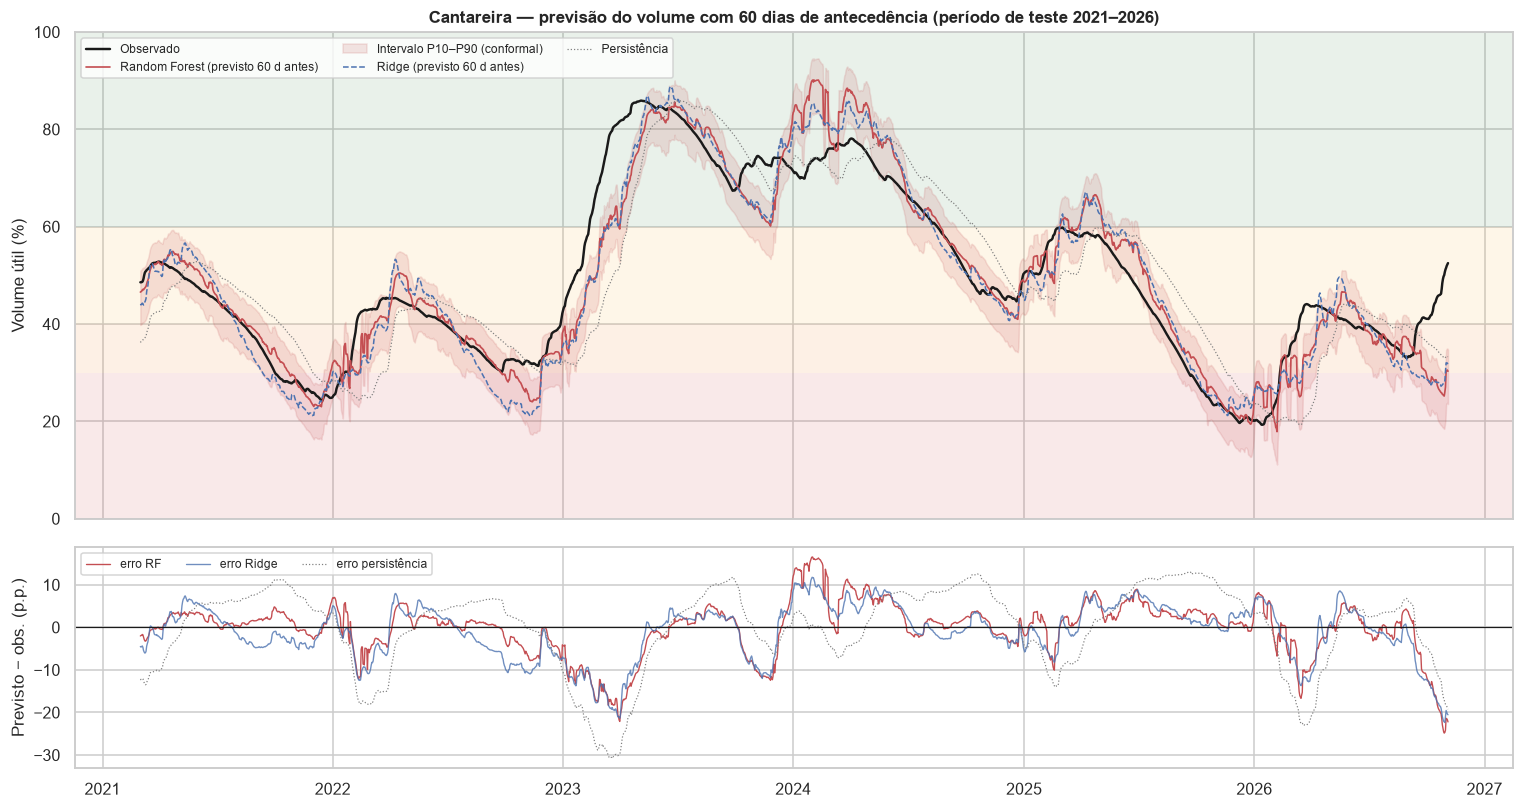

In [20]:
h = 60
p = prev_reg[h].set_index("data_alvo")
lo, hi = interval[(h, "RandomForest")]
fig, axes = plt.subplots(2, 1, figsize=(14, 7.5), gridspec_kw={"height_ratios": [2.2, 1]}, sharex=True)
ax = axes[0]; faixas(ax)
ax.plot(p.index, p.obs, color="k", lw=1.6, label="Observado")
ax.plot(p.index, p["RandomForest"], color="C3", lw=1.1, label="Random Forest (previsto 60 d antes)")
ax.fill_between(p.index, p["RandomForest"] + lo, p["RandomForest"] + hi, color="C3", alpha=0.15,
                label="Intervalo P10–P90 (conformal)")
ax.plot(p.index, p["Ridge"], color="C0", lw=1, ls="--", label="Ridge (previsto 60 d antes)")
ax.plot(p.index, p["Persistência (Δ=0)"], color="grey", lw=0.8, ls=":", label="Persistência")
ax.set_ylabel("Volume útil (%)"); ax.set_ylim(0, 100); ax.legend(fontsize=8, ncol=3, loc="upper left")
ax.set_title("Cantareira — previsão do volume com 60 dias de antecedência (período de teste 2021–2026)")
axes[1].plot(p.index, p["RandomForest"] - p.obs, color="C3", lw=0.9, label="erro RF")
axes[1].plot(p.index, p["Ridge"] - p.obs, color="C0", lw=0.9, label="erro Ridge", alpha=0.8)
axes[1].plot(p.index, p["Persistência (Δ=0)"] - p.obs, color="grey", lw=0.8, ls=":", label="erro persistência")
axes[1].axhline(0, color="k", lw=0.8); axes[1].set_ylabel("Previsto − obs. (p.p.)"); axes[1].legend(fontsize=8, ncol=3)
plt.tight_layout(); salvar(fig, "08_regressao_teste"); plt.show()

**Leitura do gráfico:** os modelos acompanham bem os ciclos de deplecionamento (2021, 2022 e 2025), que são graduais e dominados pela sazonalidade e pela captação. **Os maiores erros são subestimações em recuperações rápidas** (início de 2023, fevereiro de 2026 e setembro a outubro de 2026, com até −22 p.p.), causadas por chuvas extremas que não podem ser conhecidas 60 dias antes. **Do ponto de vista do risco, esse tipo de erro é conservador**: o modelo é pessimista quando o futuro é melhor. Antes das crises de 2021, 2022 e 2025, os erros otimistas ficaram em geral abaixo de 8 p.p. O maior erro otimista (+16 p.p., início de 2024) ocorreu com o volume alto, fora da zona de risco.

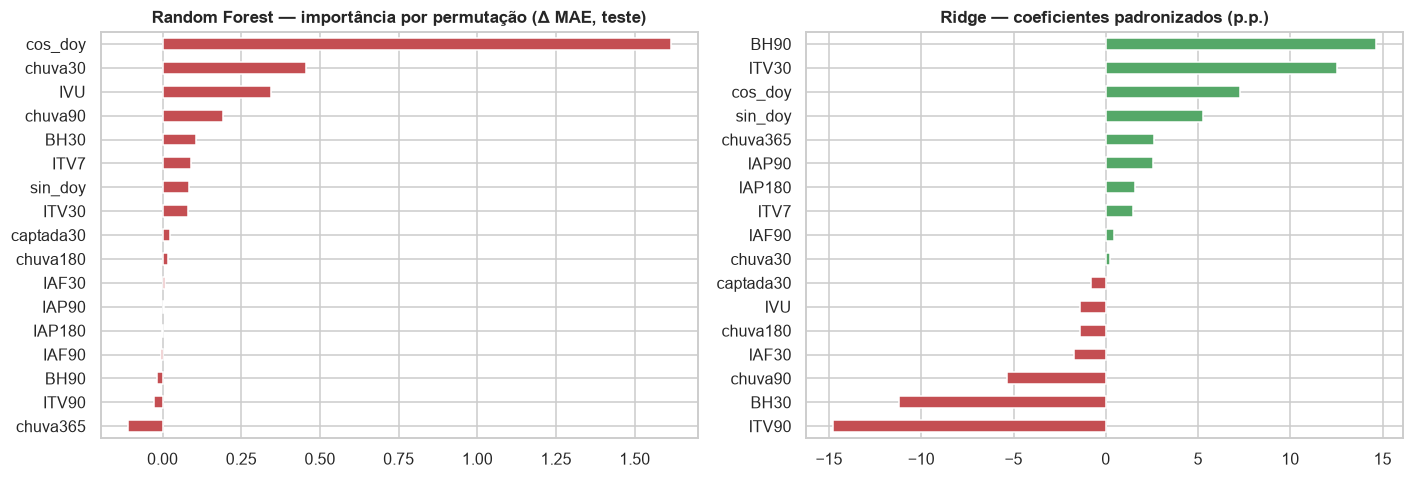

In [21]:
rf60 = modelos_reg[60]["RandomForest"]
pi = permutation_importance(rf60, te60[an.FEATURES], te60.y_delta, n_repeats=10,
                            random_state=SEED, scoring="neg_mean_absolute_error", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=an.FEATURES).sort_values()
coef = pd.Series(modelos_reg[60]["Ridge"][-1].coef_, index=an.FEATURES).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
imp.plot.barh(ax=axes[0], color="C3"); axes[0].set_title("Random Forest — importância por permutação (Δ MAE, teste)")
coef.plot.barh(ax=axes[1], color=np.where(coef > 0, "C2", "C3")); axes[1].set_title("Ridge — coeficientes padronizados (p.p.)")
plt.tight_layout(); salvar(fig, "09_importancia"); plt.show()

**Interpretação das variáveis:** na RF, a **sazonalidade (cos_doy)** é de longe a variável mais importante, seguida da chuva recente (30 e 90 dias), do volume atual e do balanço de 30 dias. Isso confirma a EDA: o sinal de 60 dias vem sobretudo da época do ano e das condições recentes. Na Ridge, os coeficientes grandes e de sinais opostos de variáveis correlacionadas (BH90 contra ITV90, BH30 contra ITV30) indicam **multicolinearidade**. Os coeficientes isolados não devem ser interpretados causalmente.

### 7.2 Classificação: o Cantareira estará abaixo de 40 % daqui a 60 dias?

**Escolha das métricas e custo dos erros.** Em um sistema de alerta hídrico, um **falso negativo** (crise não sinalizada) custa muito mais que um **falso positivo** (alerta preventivo que não se confirma). Um falso negativo tira dos gestores semanas de margem para medidas graduais. Um falso positivo custa monitoramento mais intenso. Por isso:
- o limiar de decisão τ foi escolhido **na validação** como o maior valor que ainda garante **recall ≥ 90 %**;
- a métrica-resumo é o **F2**, que pondera o recall 4 vezes mais que a precisão; também são reportados PR-AUC e Brier (calibração);
- os resultados são mostrados para todas as amostras e para o subconjunto em que **hoje o volume ainda está ≥ 40 %**, que é onde antecipar faz diferença. Nos demais casos, "continuar abaixo de 40 %" é quase trivial.

In [22]:
X = an.FEATURES
tr, va, te = tr60.dropna(subset=["y_evento"]), va60.dropna(subset=["y_evento"]), te60
cands = {"LogReg": [LogisticRegression(C=c, class_weight="balanced", max_iter=5000) for c in (0.01, 0.1, 1.0)],
         "RandomForest": [RandomForestClassifier(n_estimators=400, min_samples_leaf=l, max_features=0.5,
                                                 class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
                          for l in (10, 30, 60, 120)]}
escolhidos, limiares, proba_val = {}, {}, {}
for nome, lista in cands.items():
    melhor, best_ap = None, -1
    for est in lista:
        m = make_pipeline(StandardScaler(), est).fit(tr[X], tr.y_evento)
        ap = average_precision_score(va.y_evento, m.predict_proba(va[X])[:, 1])
        if ap > best_ap:
            melhor, best_ap = est, ap
    m = make_pipeline(StandardScaler(), melhor).fit(tr[X], tr.y_evento)
    pv = m.predict_proba(va[X])[:, 1]
    # limiar: maior probabilidade que ainda garante recall >= 90% na validacao
    prec, rec, thr = precision_recall_curve(va.y_evento, pv)
    ok = np.where(rec[:-1] >= 0.90)[0]
    limiares[nome] = float(thr[ok[-1]]) if len(ok) else 0.5
    escolhidos[nome] = melhor
    proba_val[nome] = pd.Series(pv, index=va.index)
    print(f"{nome}: hiperparâmetro escolhido = {melhor} | AP validação = {best_ap:.3f} | limiar τ = {limiares[nome]:.3f}")

trva = pd.concat([tr, va])
clf = {n: make_pipeline(StandardScaler(), e).fit(trva[X], trva.y_evento) for n, e in escolhidos.items()}
proba = {n: m.predict_proba(te[X])[:, 1] for n, m in clf.items()}

def metr_clf(y, yhat, score, nome, subset="todos"):
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return {"modelo": nome, "amostras": subset, "recall": recall_score(y, yhat, zero_division=0),
            "precisão": precision_score(y, yhat, zero_division=0), "F2": fbeta_score(y, yhat, beta=2, zero_division=0),
            "PR-AUC": average_precision_score(y, score) if y.nunique() > 1 else np.nan,
            "Brier": brier_score_loss(y, score) if score is not None else np.nan,
            "VP": tp, "FN (crise não detectada)": fn, "FP (alarme falso)": fp, "VN": tn}

y = te.y_evento.astype(int)
transicao = te.IVU >= 40     # hoje fora do Alerta: e aqui que antecipar faz diferenca
res_clf = []
for sub_nome, msk in (("todos", slice(None)), ("V(t) ≥ 40%", transicao)):
    base = (te.IVU < 40).astype(int)
    res_clf.append(metr_clf(y[msk], base[msk], base[msk].astype(float), "Baseline: V(t)<40 (persistência)", sub_nome))
    base45 = (te.IVU < 45).astype(int)
    res_clf.append(metr_clf(y[msk], base45[msk], base45[msk].astype(float), "Baseline: V(t)<45", sub_nome))
    for n in clf:
        yh = (proba[n] >= limiares[n]).astype(int)
        res_clf.append(metr_clf(y[msk], pd.Series(yh, index=te.index)[msk],
                                pd.Series(proba[n], index=te.index)[msk], n, sub_nome))
res_clf = pd.DataFrame(res_clf).set_index(["amostras", "modelo"])
res_clf.round(3)

LogReg: hiperparâmetro escolhido = LogisticRegression(C=0.01, class_weight='balanced', max_iter=5000) | AP validação = 0.924 | limiar τ = 0.680


RandomForest: hiperparâmetro escolhido = RandomForestClassifier(class_weight='balanced_subsample', max_features=0.5,
                       min_samples_leaf=30, n_estimators=400, n_jobs=-1,
                       random_state=42) | AP validação = 0.866 | limiar τ = 0.606


recall  precisão   F2  PR-AUC  Brier   VP  FN (crise não detectada)  FP (alarme falso)    VN
amostras   modelo                                                                                                                        
todos      Baseline: V(t)<40 (persistência)    0.65      0.65 0.65    0.54   0.23  451                       240                242  1141
           Baseline: V(t)<45                   0.92      0.64 0.85    0.62   0.20  638                        53                356  1027
           LogReg                              0.76      0.80 0.77    0.90   0.11  523                       168                131  1252
           RandomForest                        0.92      0.79 0.89    0.92   0.09  635                        56                165  1218
V(t) ≥ 40% Baseline: V(t)<40 (persistência)    0.00      0.00 0.00    0.17   0.17    0                       240                  0  1141
           Baseline: V(t)<45                   0.78      0.62 0.74    0.52   0.12  187                        53                114  1027
           LogReg                              0.31      0.96 0.36    0.84   0.08   75                       165                  3  1138
           RandomForest                        0.81      0.87 0.82    0.92   0.06  194                        46                 28  1113

**Análise crítica da classificação (teste 2021–2026):**
- **A Random Forest é o melhor classificador**: recall de 0,92, precisão de 0,79, F2 de 0,89 e PR-AUC de 0,92. Ela deixou de sinalizar 56 de 691 dias com evento.
- O baseline de persistência (V(t) < 40) erra todas as transições: recall de 0,65 no total e **0 nas amostras em que o volume ainda estava acima de 40 %**.
- O baseline "V(t) < 45 %" tem recall alto (0,92), mas **gera mais que o dobro de alarmes falsos** (356 contra 165). Nas transições, a RF tem recall de 0,81 com precisão de 0,87, contra 0,78 e 0,62 do baseline. **O modelo acrescenta informação além do volume atual.**
- **A regressão logística teve boa ordenação dos casos (PR-AUC de 0,90), mas o limiar não se transferiu para o teste**: o recall caiu de 0,90 na validação para 0,76, e para 0,31 nas transições. É um exemplo de **deriva entre períodos**: o limiar precisa ser recalibrado periodicamente.
- O Brier da RF (0,09) é menor que o dos baselines, ou seja, as probabilidades são mais confiáveis.

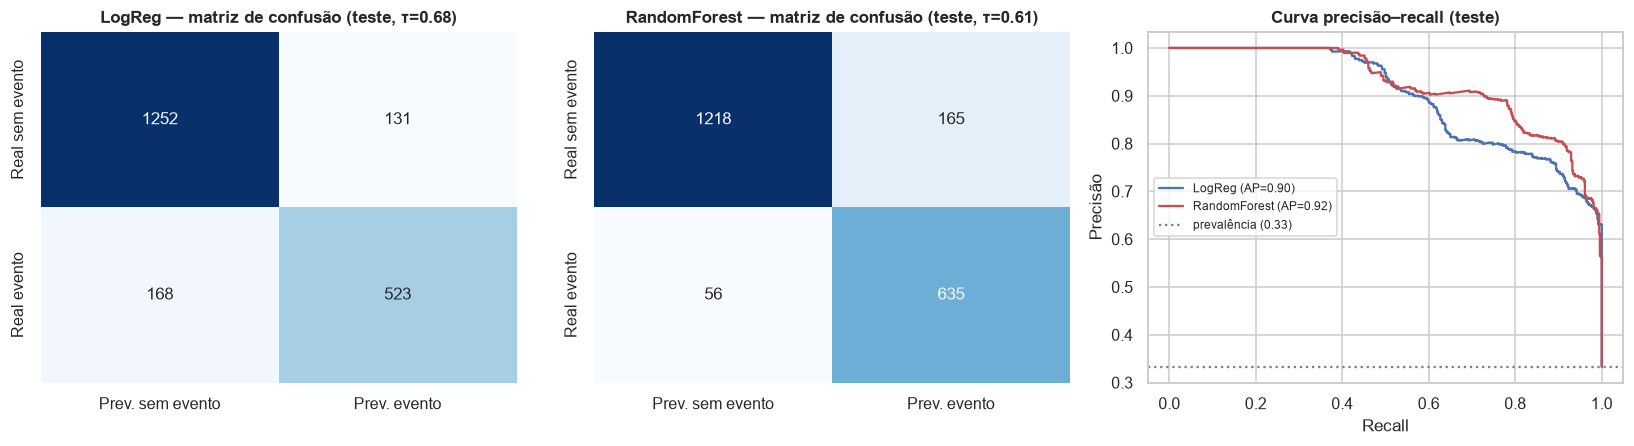

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, n in zip(axes[:2], clf):
    yh = (proba[n] >= limiares[n]).astype(int)
    cm = confusion_matrix(y, yh, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Prev. sem evento", "Prev. evento"], yticklabels=["Real sem evento", "Real evento"])
    ax.set_title(f"{n} — matriz de confusão (teste, τ={limiares[n]:.2f})")
for n, c in zip(clf, ["C0", "C3"]):
    pr, rc, _ = precision_recall_curve(y, proba[n])
    axes[2].plot(rc, pr, color=c, label=f"{n} (AP={average_precision_score(y, proba[n]):.2f})")
axes[2].axhline(y.mean(), color="grey", ls=":", label=f"prevalência ({y.mean():.2f})")
axes[2].set(xlabel="Recall", ylabel="Precisão", title="Curva precisão–recall (teste)"); axes[2].legend(fontsize=8)
plt.tight_layout(); salvar(fig, "10_classificacao"); plt.show()

### 7.3 Antecedência: com quantos dias de antecedência o modelo sinalizou cada entrada abaixo de 40 %?

In [24]:
# Antecedencia: para cada entrada do volume abaixo de 40% no teste, quantos dias antes o modelo alertou?
serie = ind_model.IVU
cruz = serie[(serie < 40) & (serie.shift(1) >= 40)]
cruz = [d for d in cruz.index if d > pd.Timestamp("2021-01-01") and (serie.loc[d - pd.Timedelta(days=60):d - pd.Timedelta(days=1)] >= 40).all()]
pserie = {n: pd.Series(proba[n], index=te.index) for n in clf}
antecip = []
for d in cruz:
    linha = {"entrada abaixo de 40%": d.date()}
    for n in clf:
        jan = pserie[n].loc[d - pd.Timedelta(days=120):d]
        alerta = jan[jan >= limiares[n]]
        if not len(alerta):
            txt = "não alertou"
        elif alerta.index[0] == jan.index[0]:
            txt = "≥ 120 (já em alerta no início da janela)"
        else:
            txt = str((d - alerta.index[0]).days)
        linha[f"{n}: 1º alerta (dias antes)"] = txt
    antecip.append(linha)
antecip = pd.DataFrame(antecip)
antecip

,entrada abaixo de 40%,LogReg: 1º alerta (dias antes),RandomForest: 1º alerta (dias antes)
0,2021-08-11,44,64
1,2022-06-28,14,110
2,2025-08-06,17,38
3,2026-06-03,≥ 120 (já em alerta no início da janela),≥ 120 (já em alerta no início da janela)


**Resultado:** nas quatro entradas do Cantareira abaixo de 40 % no período de teste, a **Random Forest sinalizou o evento antes em todas elas**: 64, 110, 38 e mais de 120 dias antes. Na de 2026, o sistema estava em alerta desde a crise de 2025. A regressão logística sinalizou mais tarde (14 a 44 dias). Em agosto de 2025, a RF deu **38 dias de aviso** antes de o Cantareira entrar na faixa de Alerta, que levou ao mínimo de 19,3 %.

---
## 8. Identificação de riscos e emissão de alertas

### 8.1 Critérios documentados
**Nível base**, pelo volume útil atual, seguindo as faixas da Resolução Conjunta ANA/DAEE nº 925/2017 para o Cantareira (as faixas 4 e 5 foram agrupadas em "Crítico"):

| Nível | Volume útil | Faixa ANA/DAEE | Significado para a gestão |
|---|---|---|---|
| 🟢 **Normal** | ≥ 60 % | Faixa 1 | comportamento de referência |
| 🟡 **Atenção** | 40–60 % | Faixa 2 | possível deterioração; acompanhamento mais frequente |
| 🟠 **Alerta** | 30–40 % | Faixa 3 | risco aumentado; avaliação pelos responsáveis |
| 🔴 **Crítico** | < 30 % | Faixas 4–5 | risco elevado de escassez; avaliação prioritária |

Para os demais sistemas os mesmos limiares servem como **referência**, sem caráter regulatório.

**Escalonamento preditivo:** o nível sobe **um** degrau se um gatilho preditivo disparar. O modelo **nunca rebaixa** o nível dado pelo volume atual. Cinco regras candidatas foram comparadas **no período de validação (2017–2020)**:

| Regra | Gatilhos de escalonamento |
|---|---|
| A | nenhum (só o volume atual) |
| B | classificador RF: P(V(t+60) < 40 %) ≥ τ |
| C | B + previsão central da RF para V(t+60) em faixa pior que a atual |
| D | B + cenário pessimista (P10) em faixa pior |
| E | D + IRH ≥ 75 |

**Critério de escolha:** a regra com **menor sub-alerta** (nível emitido abaixo do nível real 60 dias depois), desde que o **sobre-alerta** não passe de **30 % dos dias**. Esse limite existe para evitar a *fadiga de alerta*: quando os alertas são emitidos com frequência excessiva, os gestores deixam de levá-los a sério.

In [25]:
MODELO_ALERTA = "RandomForest"
TAU = limiares[MODELO_ALERTA]
lo60, hi60 = interval[(60, "RandomForest")]

GATILHOS = {"prob": "classificador: P(V(t+60)<40%) ≥ τ",
            "central": "previsão central (RF) de V(t+60) em faixa pior",
            "pess": "cenário pessimista P10 de V(t+60) em faixa pior",
            "irh": "IRH ≥ 75"}
REGRAS = {"A: só volume atual": [],
          "B: A + classificador": ["prob"],
          "C: B + previsão central": ["prob", "central"],
          "D: B + cenário pessimista": ["prob", "pess"],
          "E: D + IRH≥75": ["prob", "pess", "irh"]}

def nivel_final(ivu, gatilhos, prob=np.nan, v_cent=np.nan, v_pess=np.nan, irh=np.nan):
    """Nivel base = faixa do volume atual. Se qualquer gatilho ativo disparar,
    o nivel sobe UM degrau (max. Critico). O modelo nunca rebaixa o nivel."""
    base = an.nivel_idx(an.nivel_por_volume(ivu))
    pior = lambda v: not np.isnan(v) and an.nivel_idx(an.nivel_por_volume(v)) > base
    motivos = []
    if "prob" in gatilhos and not np.isnan(prob) and prob >= TAU:
        motivos.append(f"P(V60<40%)={prob:.0%}")
    if "central" in gatilhos and pior(v_cent):
        motivos.append(f"previsão 60 d={v_cent:.0f}%")
    if "pess" in gatilhos and pior(v_pess):
        motivos.append(f"P10 60 d={v_pess:.0f}%")
    if "irh" in gatilhos and not np.isnan(irh) and irh >= 75:
        motivos.append(f"IRH={irh:.0f}")
    return an.NIVEIS[min(base + (1 if motivos else 0), 3)], "; ".join(motivos) or "-"

def avaliar_regras(bloco, prob, delta):
    df = pd.DataFrame({"IVU": bloco.IVU, "prob": prob, "cent": bloco.IVU + delta,
                       "pess": bloco.IVU + delta + lo60, "IRH": ind_model.IRH.reindex(bloco.index),
                       "real": bloco.y_vol.map(an.nivel_por_volume).map(an.nivel_idx)})
    linhas, niveis = [], {}
    for nome, g in REGRAS.items():
        nv = [nivel_final(r.IVU, g, r.prob, r.cent, r.pess, r.IRH)[0] for r in df.itertuples()]
        e = pd.Series(nv, index=df.index).map(an.nivel_idx)
        niveis[nome] = pd.Series(nv, index=df.index)
        linhas.append({"regra": nome, "sub-alerta (emitido < real em t+60)": (e < df.real).mean(),
                       "exato": (e == df.real).mean(), "sobre-alerta (emitido > real)": (e > df.real).mean(),
                       "sub-alerta grave (≥2 níveis abaixo)": (e <= df.real - 2).mean()})
    return pd.DataFrame(linhas).set_index("regra"), niveis, df

# 1) escolha da regra na VALIDACAO (2017-2020), com modelos treinados so no treino
aval_val, _, _ = avaliar_regras(va60, proba_val[MODELO_ALERTA], pred_val[60])
# criterio: menor sub-alerta, desde que o sobre-alerta fique <= 30% dos dias (limite de "fadiga de alerta")
LIMITE_SOBRE_ALERTA = 0.30
elegiveis = aval_val[aval_val["sobre-alerta (emitido > real)"] <= LIMITE_SOBRE_ALERTA]
REGRA = elegiveis["sub-alerta (emitido < real em t+60)"].idxmin()
GATILHOS_ATIVOS = REGRAS[REGRA]
print("Regra escolhida na validação:", REGRA, "| gatilhos:", [GATILHOS[g] for g in GATILHOS_ATIVOS])
(aval_val * 100).round(1)

Regra escolhida na validação: C: B + previsão central | gatilhos: ['classificador: P(V(t+60)<40%) ≥ τ', 'previsão central (RF) de V(t+60) em faixa pior']


,sub-alerta (emitido < real em t+60),exato,sobre-alerta (emitido > real),sub-alerta grave (≥2 níveis abaixo)
regra,,,,
A: só volume atual,20.60,65.30,14.10,0.00
B: A + classificador,10.60,60.70,28.70,0.00
C: B + previsão central,6.10,65.20,28.70,0.00
D: B + cenário pessimista,0.30,58.70,41.00,0.00
E: D + IRH≥75,0.30,58.70,41.00,0.00


**Escolha:** na validação, a **regra C** (classificador + previsão central) reduz o sub-alerta de 20,6 % (só volume) para **6,1 %**, mantendo o sobre-alerta em 28,7 %. As regras D e E quase eliminam o sub-alerta (0,3 %), mas sobre-alertam em 41 % dos dias e foram descartadas pelo critério de fadiga. A regra E é idêntica à D: o IRH não acrescentou sinal, o que confirma a seção 6.1.

### 8.2 Avaliação da regra no período de teste (2021–2026)

In [26]:
# 2) desempenho das regras no TESTE (2021-2026), modelos reajustados em treino+validacao
p60 = pd.Series(proba[MODELO_ALERTA], index=te.index)
d60 = pd.Series(modelos_reg[60]["RandomForest"].predict(te[X]), index=te.index)
aval_te, niveis_te, base_te = avaliar_regras(te, p60, d60)
hist = base_te.assign(V_fut=te.y_vol, nivel=niveis_te[REGRA], nivel_base=niveis_te["A: só volume atual"])
hist["escalonado"] = hist.nivel != hist.nivel_base
print(f"Regra {REGRA}: escalonamento em {hist.escalonado.mean():.1%} dos dias do teste")
(aval_te * 100).round(1)

Regra C: B + previsão central: escalonamento em 31.8% dos dias do teste


,sub-alerta (emitido < real em t+60),exato,sobre-alerta (emitido > real),sub-alerta grave (≥2 níveis abaixo)
regra,,,,
A: só volume atual,19.10,64.70,16.20,1.20
B: A + classificador,6.30,67.90,25.80,0.00
C: B + previsão central,3.10,71.10,25.80,0.00
D: B + cenário pessimista,1.20,60.50,38.40,0.00
E: D + IRH≥75,1.20,60.50,38.40,0.00


**Resultado no teste:** a regra C, escolhida sem olhar o teste, **reduziu o sub-alerta de 19,1 % para 3,1 %** e **eliminou o sub-alerta grave** (2 ou mais níveis abaixo do real caiu de 1,2 % para 0 %). O acerto exato subiu de 64,7 % para 71,1 %. O custo foi o sobre-alerta, que passou de 16,2 % para 25,8 % dos dias, um custo aceitável em um sistema preventivo. O escalonamento ocorreu em cerca de 32 % dos dias, quase todos nos períodos de deplecionamento de 2021, 2022 e 2025.

**Incertezas consideradas:** (i) o intervalo P10–P90 acompanha toda previsão; (ii) o limiar τ e o intervalo vêm de períodos passados e sofrem deriva, por isso precisam de recalibração anual; (iii) o alerta é uma **recomendação**, e o gatilho que o motivou é sempre informado para que o gestor possa auditá-lo.

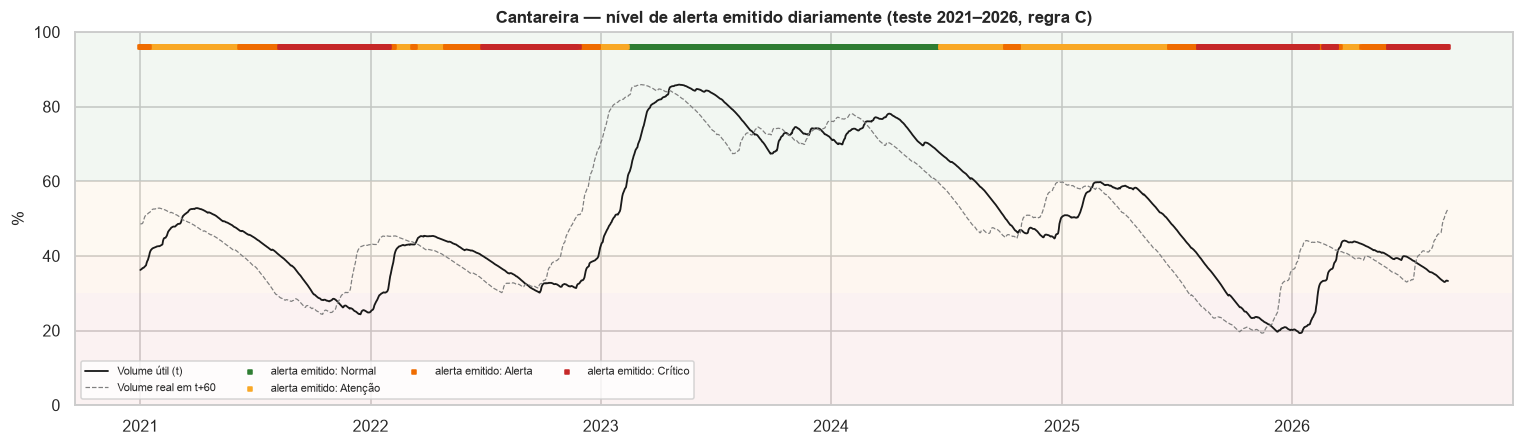

In [27]:
fig, ax = plt.subplots(figsize=(14, 4.2))
faixas(ax, alpha=0.06)
ax.plot(hist.index, hist.IVU, color="k", lw=1.2, label="Volume útil (t)")
ax.plot(hist.index, hist.V_fut, color="grey", lw=0.8, ls="--", label="Volume real em t+60")
for nv in an.NIVEIS:
    m = hist.nivel == nv
    ax.scatter(hist.index[m], np.full(m.sum(), 96), color=CN[nv], s=6, marker="s", label=f"alerta emitido: {nv}")
ax.set(ylim=(0, 100), ylabel="%", title=f"Cantareira — nível de alerta emitido diariamente (teste 2021–2026, regra {REGRA[:1]})")
ax.legend(fontsize=7.5, ncol=4, loc="lower left")
plt.tight_layout(); salvar(fig, "11_historico_alertas"); plt.show()

**Leitura do histórico de alertas:** os alertas sobem para Alerta ou Crítico **antes** de o volume cruzar os limiares em 2021, 2022 e 2025, e o nível Normal só aparece no período de abundância de 2023–2024. O padrão é o esperado de um sistema preventivo: avisa cedo e só baixa o nível quando o volume de fato se recupera.

---
## 9. Situação atual (04/11/2026) e previsão

Para a previsão operacional, os modelos são **reajustados com todo o histórico** que tem alvo conhecido. A incerteza vem dos resíduos fora da amostra do período de teste.

In [28]:
# Modelo operacional: reajusta com todas as amostras com alvo conhecido e preve a partir da ultima data
X = an.FEATURES
ult = ind_model.loc[[ultima], X]
prev_atual = {}
for h in HORIZONTES:
    ds = an.montar_dataset(ind_model, h, quebras=quebras_c).dropna(subset=X + ["y_delta"])
    rf_op = RandomForestRegressor(n_estimators=300, min_samples_leaf=modelos_reg[h]["leaf"], max_features=0.5,
                                  n_jobs=-1, random_state=SEED).fit(ds[X], ds.y_delta)
    pt = prev_reg[h]
    res_te = (pt.obs - pt["RandomForest"])          # residuos fora da amostra (teste) -> incerteza
    q10, q90 = np.quantile(res_te, [0.10, 0.90])
    v = float(ult.IVU.iloc[0] + rf_op.predict(ult)[0])
    prev_atual[h] = {"data_alvo": (ultima + pd.Timedelta(days=h)).date(), "previsto_%": v,
                     "P10_%": v + q10, "P90_%": v + q90, "nível previsto": an.nivel_por_volume(v)}
    if h == 60:
        ds_c = ds.dropna(subset=["y_evento"])
        clf_op = make_pipeline(StandardScaler(), escolhidos[MODELO_ALERTA]).fit(ds_c[X], ds_c.y_evento)
        prob_atual = float(clf_op.predict_proba(ult)[0, 1])
prev_atual = pd.DataFrame(prev_atual).T
print(f"Cantareira em {ultima:%d/%m/%Y}: {ult.IVU.iloc[0]:.1f}% | P(V(t+60) < 40%) = {prob_atual:.1%} (τ = {TAU:.2f})")
prev_atual

Cantareira em 04/11/2026: 52.5% | P(V(t+60) < 40%) = 0.7% (τ = 0.61)


,data_alvo,previsto_%,P10_%,P90_%,nível previsto
30,2026-12-04,58.56,55.09,63.45,Atenção
60,2027-01-03,61.22,55.01,71.12,Normal
90,2027-02-02,65.11,55.98,75.51,Normal


**Previsão para o Cantareira:** partindo de 52,5 % e com afluência muito acima da média (IAF90 de 172 %), a RF projeta **cerca de 59 % em 04/12/2026, 61 % em 03/01/2027 e 65 % em 02/02/2027**. Mesmo o cenário pessimista (P10) fica em **cerca de 55 %**, dentro da faixa de Atenção. A probabilidade de o sistema estar abaixo de 40 % em 60 dias é de **0,7 %**, muito abaixo do limiar τ = 0,61. Assim, **nenhum gatilho preditivo foi acionado**.

In [29]:
painel = []
for sis in ordem:
    i = inds[sis].loc[ultima]
    c = sis == "Cantareira"   # modelos disponiveis apenas para o Cantareira
    nv, mot = nivel_final(i.IVU, GATILHOS_ATIVOS,
                          prob=prob_atual if c else np.nan,
                          v_cent=prev_atual.loc[60, "previsto_%"] if c else np.nan,
                          v_pess=prev_atual.loc[60, "P10_%"] if c else np.nan, irh=i.IRH)
    painel.append({"sistema": sis, "IVU (%)": i.IVU, "ITV30 (p.p.)": i.ITV30, "IAP90 (%)": i.IAP90,
                   "IAF90 (%)": i.IAF90, "BH30 (hm³)": i.BH30,
                   "AUT (dias)": "sem déficit" if np.isnan(i.AUT) else f"{i.AUT:.0f}",
                   "IRH": i.IRH, "nível pelo volume": an.nivel_por_volume(i.IVU),
                   "NÍVEL DE ALERTA": nv, "gatilhos de escalonamento": mot})
painel = pd.DataFrame(painel).set_index("sistema")
painel.to_csv(RAIZ / "outputs/painel_alertas_atual.csv", encoding="utf-8-sig")
def cor_nivel(v):
    return f"background-color: {CN.get(v, 'white')}; color: white; font-weight: bold" if v in CN else ""
painel.style.format(precision=1).map(cor_nivel, subset=["nível pelo volume", "NÍVEL DE ALERTA"])

,IVU (%),ITV30 (p.p.),IAP90 (%),IAF90 (%),BH30 (hm³),AUT (dias),IRH,nível pelo volume,NÍVEL DE ALERTA,gatilhos de escalonamento
sistema,,,,,,,,,,
Cantareira,52.5,11.4,211.8,171.6,111.9,sem déficit,18.4,Atenção,Atenção,-
Alto Tietê,60.5,6.2,239.8,261.2,32.0,sem déficit,13.2,Normal,Normal,-
Guarapiranga,89.8,-5.3,261.3,289.3,-9.1,507,13.9,Normal,Normal,-
Rio Grande,96.2,1.3,251.0,194.0,1.3,sem déficit,11.4,Normal,Normal,-
Cotia,102.7,11.4,279.0,317.5,-3.5,145,9.4,Normal,Normal,-
Rio Claro,60.7,5.0,166.9,174.2,8.8,sem déficit,49.3,Normal,Normal,-
São Lourenço,74.2,-5.3,241.0,164.0,-4.7,423,30.2,Normal,Normal,-
SIM (Integrado),62.1,7.0,nan,195.3,304.4,sem déficit,20.5,Normal,Normal,-


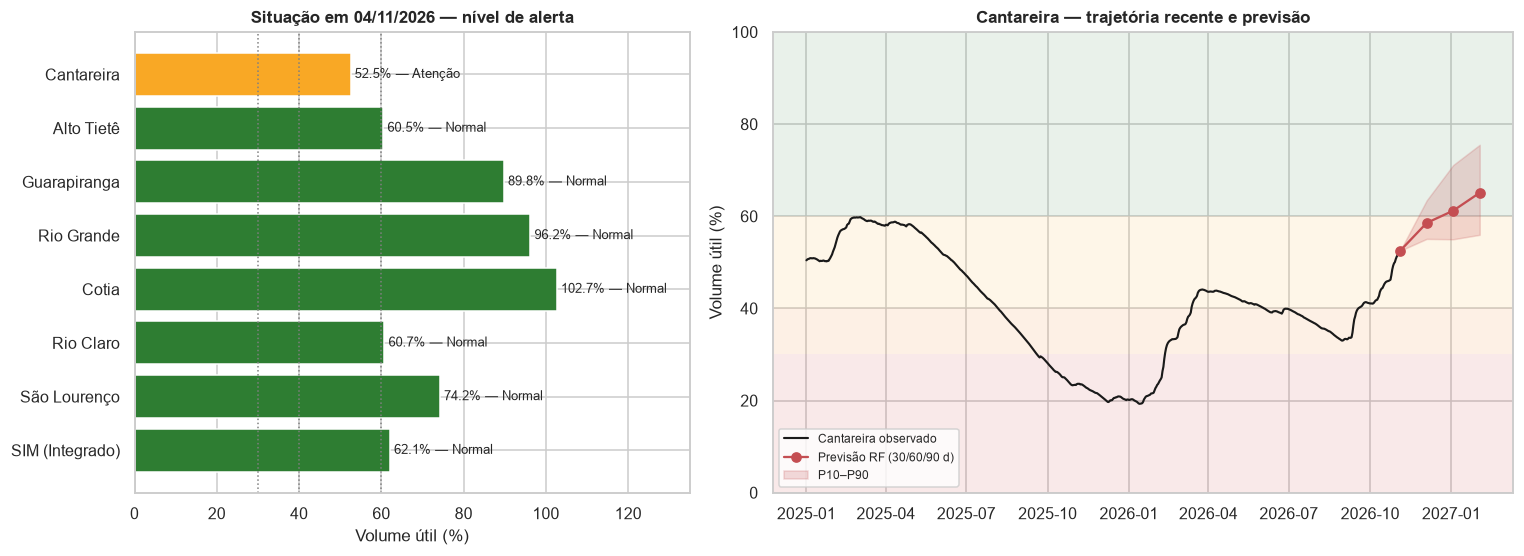

In [30]:
fig = plt.figure(figsize=(14, 5.2))
gs = fig.add_gridspec(1, 2, width_ratios=[1.05, 1.4])
ax = fig.add_subplot(gs[0])
pp = painel.iloc[::-1]
ax.barh(pp.index, pp["IVU (%)"], color=[CN[n] for n in pp["NÍVEL DE ALERTA"]])
for y_, (v, nv) in enumerate(zip(pp["IVU (%)"], pp["NÍVEL DE ALERTA"])):
    ax.text(v + 1, y_, f"{v:.1f}% — {nv}", va="center", fontsize=8.5)
for lim in (30, 40, 60):
    ax.axvline(lim, color="grey", ls=":", lw=1)
ax.set(xlim=(0, 135), xlabel="Volume útil (%)", title=f"Situação em {ultima:%d/%m/%Y} — nível de alerta")
ax2 = fig.add_subplot(gs[1]); faixas(ax2)
hc = inds["Cantareira"].IVU.loc["2025-01-01":]
ax2.plot(hc.index, hc, color="k", lw=1.4, label="Cantareira observado")
pa = prev_atual
dts = [pd.Timestamp(ultima)] + [pd.Timestamp(d) for d in pa.data_alvo]
ax2.plot(dts, [hc.iloc[-1]] + list(pa["previsto_%"]), "o-", color="C3", label="Previsão RF (30/60/90 d)")
ax2.fill_between(dts, [hc.iloc[-1]] + list(pa["P10_%"]), [hc.iloc[-1]] + list(pa["P90_%"]), color="C3", alpha=0.2, label="P10–P90")
ax2.set(ylim=(0, 100), ylabel="Volume útil (%)", title="Cantareira — trajetória recente e previsão")
ax2.legend(fontsize=8, loc="lower left")
plt.tight_layout(); salvar(fig, "12_painel_atual"); plt.show()

**Painel de situação (recomendação para avaliação humana):**
- 🟡 **Cantareira: ATENÇÃO** (52,5 %). Está em recuperação, mas **um ano hidrológico seco a partir deste nível o levaria de novo à faixa de Alerta**: a variação média acumulada de abril a setembro é de cerca de −16 p.p.
- 🟢 **Alto Tietê (60,5 %) e Rio Claro (60,7 %): NORMAL, no limite da faixa de Atenção.** Os dois estiveram abaixo de 20 % há menos de um ano (18,0 % e 13,1 %).
- 🟢 Guarapiranga (89,8 %), Rio Grande (96,2 %), Cotia (102,7 %) e São Lourenço (74,2 %): **Normal**.
- 🟢 **SIM: Normal (62,1 %)**. Há um ano estava em 25,9 %.

---
## 10. Conclusões, recomendações e limitações

### Resposta à pergunta de pesquisa
**Sim, com 60 dias de antecedência e com ressalvas.** Usando apenas dados públicos de armazenamento, chuva e vazões:
- a **Random Forest** prevê o volume do Cantareira em 60 dias com **MAE de 4,5 p.p.** (2,6 p.p. no regime crítico), 41 % melhor que a persistência;
- o classificador identifica **92 % dos dias** em que o volume estará abaixo de 40 % em 60 dias (precisão de 79 %) e sinalizou **todas as quatro** entradas na faixa de Alerta no período de teste, com **38 a mais de 120 dias** de antecedência;
- combinado às faixas regulatórias, o sistema de alerta reduziu os dias com nível subestimado de **19 % para 3 %**.

**Ressalvas:** (i) chuvas extremas e recuperações rápidas não são previsíveis com 60 dias de antecedência, mas esse erro é conservador; (ii) acima de 60 dias a incerteza é da ordem de uma faixa inteira; (iii) os limiares de decisão sofrem deriva e precisam de recalibração.

### Principais evidências
1. **Sazonalidade marcada:** a captação supera a afluência de maio a outubro. O volume no fim da estação chuvosa (março) é o melhor indicador do risco no ano seguinte.
2. **Chuva de equilíbrio de cerca de 1.400 mm/ano no Cantareira**, acima da média de 2000–2025. Com a captação atual, o sistema perde volume na maioria dos anos com chuva normal.
3. **As crises são regionais e sincronizadas** (2003, 2014–15, 2021, 2025), o que limita a compensação entre sistemas.
4. **A resposta do volume à chuva chega com cerca de um mês de atraso**. Esse sinal sustenta previsões úteis de 30 a 90 dias.

### Recomendações aos gestores (para avaliação)
1. **Manter o Cantareira em acompanhamento intensificado (Atenção)** até o fim da estação chuvosa. A meta de referência é chegar a **março de 2027 acima de 60 %**. Se a chuva de dezembro a fevereiro ficar abaixo da média (IAP90 < 80 %), reavaliar.
2. **Monitorar o Alto Tietê e o Rio Claro**, que estão no limite da faixa de Atenção e tiveram mínimos abaixo de 20 % há menos de um ano.
3. **Acompanhar semanalmente o IAP90, o IAF90 e o BH30** durante a estação seca de 2027. Eles mudam semanas antes do volume.
4. **Planejar a operação a partir do balanço anual:** como a captação atual exige chuva acima da média, vale avaliar com os órgãos competentes medidas estruturais de longo prazo, como redução de perdas, reúso e diversificação de mananciais.
5. **Recalibrar anualmente** o limiar τ e os intervalos de previsão, e auditar os alertas emitidos contra o que de fato ocorreu.

### Limitações e vieses
- **Dados não consistidos** (`isValid = false`) e **redefinições do volume útil** (2004 no Cantareira; várias no Alto Tietê e no SIM). Por causa delas, os percentuais de períodos diferentes não são estritamente comparáveis.
- **Poucos eventos independentes**: são cerca de 5 crises em 26 anos. As amostras diárias são muito autocorrelacionadas, então o tamanho efetivo da amostra é bem menor que o número de linhas, e as métricas têm incerteza considerável.
- **Não estacionariedade**: mudanças climáticas, de demanda e de regras operacionais (por exemplo, a renovação da outorga do Cantareira em 2017 e a entrada do São Lourenço em 2018) podem alterar as relações aprendidas.
- **Variáveis ausentes**: previsões meteorológicas sazonais, demanda e transferências entre sistemas (como a interligação Jaguari–Atibainha) não foram incluídas.
- **Cobertura**: os modelos preditivos foram feitos só para o Cantareira; nos demais sistemas o alerta usa as faixas de volume. Os dados do SIBH cobrem só o período a partir de 2015.

### Responsabilidade, privacidade e supervisão humana
- Os dados são **públicos, agregados e hidrológicos**. Não há dados pessoais e não há implicações diretas de privacidade (LGPD).
- **Supervisão humana obrigatória:** os níveis de alerta são **recomendações** para os gestores competentes (Sabesp, SP Águas, ANA e o órgão regulador). Eles **não confirmam uma crise** e **não autorizam restrições** no abastecimento. Toda decisão sobre redução de oferta ou racionamento exige análise técnica e validação humana.
- **Transparência:** cada alerta informa o gatilho que o motivou (probabilidade, previsão ou volume), o que permite auditoria.
- **Equidade:** medidas de restrição tendem a afetar de forma desigual as regiões periféricas e de maior cota da rede. Essa dimensão, que não é capturada pelos dados usados aqui, deve fazer parte da avaliação dos gestores.

In [31]:
resultados = {
    "data_referencia": str(ultima.date()),
    "coletado_em": meta_sabesp["coletado_em"][:10],
    "painel": painel.reset_index().to_dict(orient="records"),
    "previsao_cantareira": prev_atual.reset_index(names="horizonte").astype(str).to_dict(orient="records"),
    "prob_evento_60d": prob_atual, "tau": TAU,
    "reg": res_reg.reset_index().to_dict(orient="records"),
    "clf": res_clf.reset_index().to_dict(orient="records"),
    "antecipacao": antecip.astype(str).to_dict(orient="records"),
    "integracao": resumo_integ.reset_index().to_dict(orient="records"),
    "ano_hidro": {"spearman": rho, "p": p_rho, "inclinacao_pp_100mm": b[0] * 100, "chuva_equilibrio": -b[1] / b[0]},
    "mannwhitney": {"mediana_crise": g1.median(), "mediana_demais": g2.median(), "p": u.pvalue, "n_crise": len(g1)},
    "regra_alerta": REGRA, "aval_regras_val": aval_val.reset_index().to_dict(orient="records"),
    "aval_regras_teste": aval_te.reset_index().to_dict(orient="records"),
    "escalonamento_teste": hist.escalonado.mean(),
    "irh_validacao": pd.DataFrame(val_irh).to_dict(orient="records"),
}
(RAIZ / "outputs/resultados.json").write_text(json.dumps(resultados, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("Resultados salvos em outputs/resultados.json")

import sintese
pdf = sintese.gerar(RAIZ)
print("Síntese executiva gerada:", pdf.name)

Resultados salvos em outputs/resultados.json


Síntese executiva gerada: Sintese_Executiva_GS2026-2.pdf


### Reprodutibilidade
- Ambiente: Python 3.14; bibliotecas em `requirements.txt` (pandas, numpy, scipy, scikit-learn, matplotlib, seaborn, requests, truststore).
- Para reproduzir: `pip install -r requirements.txt` e depois executar este notebook do início ao fim. Os dados em cache (`data/raw`) garantem os mesmos resultados. Com `ATUALIZAR_DADOS = True`, os dados são baixados novamente das APIs e incluem os dias publicados depois da coleta.
- Sementes aleatórias fixas (`SEED = 42`). Saídas em `data/processed/`, `outputs/figuras/`, `outputs/painel_alertas_atual.csv` e `outputs/resultados.json`.
- Síntese executiva: `Sintese_Executiva_GS2026-2.pdf` (1 página), gerada por `src/sintese.py` a partir de `outputs/resultados.json`.

### Referências
- Sabesp. *Portal dos Mananciais: Base de Dados*. https://mananciais.sabesp.com.br/base-dados (acesso em 05/11/2026).
- SP Águas. *SIBH: Sistema Integrado de Bacias Hidrográficas*. https://apps.spaguas.sp.gov.br/sibh/ (acesso em 05/11/2026).
- ANA/DAEE. *Resolução Conjunta nº 925/2017*: condições de operação do Sistema Cantareira.
- Pedregosa et al. (2011). *Scikit-learn: Machine Learning in Python*. JMLR 12.
- Angelopoulos & Bates (2021). *A Gentle Introduction to Conformal Prediction*. arXiv:2107.07511.